In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import numpy as np

In [3]:
# Example usage:
# Load your data
import pandas as pd
metadata = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/triads_cleaned_1gbp.csv')


metadata.head()

,fmt_id,dataset,recipient_name,donor_name,pre_samples,post_samples,donor_sample,display_dataset,disease_indication,single_pre_sample,single_post_sample,single_post_timepoint,single_donor_sample,success,fresh_frozen,related_donor,route_binary,route,abx,BOWEL PREP
0,1,AggarwalaV_2021,1001166,1001175,1001166B,1001166G,1001175B,AggarwalaV_2021,rCDI,SRS9474920,SRS9474922,33,SRS9474972,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
1,2,AggarwalaV_2021,1001216,1001217,1001216B,"1001216F,1001216H,1001216I",1001217B,AggarwalaV_2021,rCDI,SRS9474898,SRS9474925,7,SRS9474924,False,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
2,3,AggarwalaV_2021,1001254,1001262,"1001254A,1001254B","1001254E,1001254F,1001254G,1001254H,1001254I,1...",1001262B,AggarwalaV_2021,rCDI,SRS9474930,SRS9474934,44,SRS9474895,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
3,4,AggarwalaV_2021,1001270,1001271,1001270B,"1001270D,1001270F,1001270H,1001270J",1001271B,AggarwalaV_2021,rCDI,SRS9474897,SRS9474909,45,SRS9474906,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)
4,5,AggarwalaV_2021,1001282,1001283,1001282B,"1001282G,1001282H",1001283B,AggarwalaV_2021,rCDI,SRS9474948,SRS9474952,27,SRS9474939,True,both,unrelated,NaN,colonoscopy or nasogastric tube,TRUE,bowel prep (unspecified)


In [6]:
# import pandas as pd
# import numpy as np

# # Load SGB details
# print("Loading SGB details...")
# sgb_details = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/cleaned_doser_results_290626_10min.csv')
# print(f"Loaded {len(sgb_details)} donor-recipient comparisons")

# # Merge with metadata to get dataset information
# print("Merging with metadata...")
# sgb_details = sgb_details.merge(
#     metadata[['single_pre_sample', 'single_post_sample', 'dataset']],
#     left_on=['pre_fmt_id', 'post_fmt_id'],
#     right_on=['single_pre_sample', 'single_post_sample'],
#     how='left'
# )

# print(f"\nCalculating transmissibility scores by dataset...")
# print("Transmissibility = (# recipients with shared strain) / (# recipients where donor had this SGB)")

# datasets_to_exclude = ['LUMINATE', 'NgS_2021', 'ShekarrizS_2025', 'CM_MORELIA', 'LeongK_2020',
#                         'KousgaardS_2024', 'QuraishiMN_2026']

# sgb_details = sgb_details[~sgb_details['display_dataset'].isin(datasets_to_exclude)].copy()

# print(f"After excluding LUMINATE and multi-donor datasets: {len(sgb_details)} comparisons")

# # Calculate transmissibility for each SGB within each dataset
# transmissibility_results = []

# for dataset in sgb_details['display_dataset'].dropna().unique():
#     dataset_data = sgb_details[sgb_details['display_dataset'] == dataset]
    
#     # For each unique recipient (post_fmt_id), track:
#     # 1. Which SGBs were in the donor(s)
#     # 2. Which SGBs were shared
    
#     sgb_in_donor = {}  # sgb -> set of post_fmt_ids where this SGB was in donor
#     sgb_shared = {}    # sgb -> set of post_fmt_ids where this SGB was shared
    
#     for _, row in dataset_data.iterrows():
#         post_id = row['post_fmt_id']
        
#         # Parse donor SGBs
#         donor_sgbs_str = row['donor_sgbs']
#         if pd.notna(donor_sgbs_str) and donor_sgbs_str != '':
#             donor_sgbs = set(donor_sgbs_str.split(','))
#             for sgb in donor_sgbs:
#                 if sgb not in sgb_in_donor:
#                     sgb_in_donor[sgb] = set()
#                 sgb_in_donor[sgb].add(post_id)
        
#         # Parse shared SGBs
#         shared_sgbs_str = row['shared_donor_post_sgbs']
#         if pd.notna(shared_sgbs_str) and shared_sgbs_str != '':
#             shared_sgbs = set(shared_sgbs_str.split(','))
#             for sgb in shared_sgbs:
#                 if sgb not in sgb_shared:
#                     sgb_shared[sgb] = set()
#                 sgb_shared[sgb].add(post_id)
    
#     # Calculate transmissibility for each SGB
#     for sgb in sgb_in_donor.keys():
#         n_recipients_with_donor_sgb = len(sgb_in_donor[sgb])
#         n_recipients_shared = len(sgb_shared.get(sgb, set()))
        
#         transmissibility = n_recipients_shared / n_recipients_with_donor_sgb if n_recipients_with_donor_sgb > 0 else 0
        
#         transmissibility_results.append({
#             'display_dataset': dataset,
#             'sgb': sgb,
#             'n_recipients_with_donor_sgb': n_recipients_with_donor_sgb,
#             'n_recipients_shared': n_recipients_shared,
#             'transmissibility': transmissibility
#         })
    
#     print(f"  {dataset}: {len(sgb_in_donor)} unique SGBs in donor samples")

# # Create dataframe
# transmissibility_df = pd.DataFrame(transmissibility_results)

# print("\n" + "="*80)
# print("TRANSMISSIBILITY STATISTICS BY DATASET")
# print("="*80)

# # Summary statistics per dataset
# for dataset in sorted(transmissibility_df['display_dataset'].unique()):
#     dataset_trans = transmissibility_df[transmissibility_df['display_dataset'] == dataset]
    
#     print(f"\n{dataset}:")
#     print(f"  Total SGBs analyzed: {len(dataset_trans)}")
#     print(f"  Mean transmissibility: {dataset_trans['transmissibility'].mean():.4f}")
#     print(f"  Median transmissibility: {dataset_trans['transmissibility'].median():.4f}")
#     print(f"  Std transmissibility: {dataset_trans['transmissibility'].std():.4f}")
    
#     # Distribution
#     high_trans = (dataset_trans['transmissibility'] >= 0.75).sum()
#     med_trans = ((dataset_trans['transmissibility'] >= 0.5) & (dataset_trans['transmissibility'] < 0.75)).sum()
#     low_trans = (dataset_trans['transmissibility'] < 0.5).sum()
    
#     print(f"  High transmissibility (≥75%): {high_trans} SGBs ({100*high_trans/len(dataset_trans):.1f}%)")
#     print(f"  Medium transmissibility (50-75%): {med_trans} SGBs ({100*med_trans/len(dataset_trans):.1f}%)")
#     print(f"  Low transmissibility (<50%): {low_trans} SGBs ({100*low_trans/len(dataset_trans):.1f}%)")
    
#     # Top 10 most transmissible SGBs (with at least 3 opportunities)
#     dataset_trans_filtered = dataset_trans[dataset_trans['n_recipients_with_donor_sgb'] >= 3]
#     if len(dataset_trans_filtered) > 0:
#         top10 = dataset_trans_filtered.nlargest(10, 'transmissibility')
#         print(f"\n  Top 10 most transmissible SGBs (min 3 recipients):")
#         for _, row in top10.iterrows():
#             print(f"    {row['sgb']}: {row['transmissibility']:.2%} ({row['n_recipients_shared']}/{row['n_recipients_with_donor_sgb']})")

# # Overall summary
# print("\n" + "="*80)
# print("OVERALL STATISTICS (all datasets)")
# print("="*80)
# print(f"Total unique SGBs analyzed: {transmissibility_df['sgb'].nunique()}")
# print(f"Mean transmissibility: {transmissibility_df['transmissibility'].mean():.4f}")
# print(f"Median transmissibility: {transmissibility_df['transmissibility'].median():.4f}")

# # Save results
# transmissibility_df.to_csv('sgb_transmissibility_by_dataset.csv', index=False)
# print(f"\nSaved results to 'sgb_transmissibility_by_dataset.csv'")

# # Create summary statistics
# summary_stats = transmissibility_df.groupby('display_dataset').agg({
#     'sgb': 'count',
#     'transmissibility': ['mean', 'median', 'std', 'min', 'max']
# }).round(4)
# summary_stats.columns = ['n_sgbs', 'mean_trans', 'median_trans', 'std_trans', 'min_trans', 'max_trans']
# summary_stats = summary_stats.reset_index()

# #summary_stats.to_csv('transmissibility_summary_by_dataset.csv', index=False)
# #print("Saved summary to 'transmissibility_summary_by_dataset.csv'")

# print("\nDataset Summary:")
# print(summary_stats.to_string(index=False))

In [4]:
import pandas as pd
import numpy as np

# Load SGB details
print("Loading SGB details...")
sgb_details = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/doser_results_for_engraftment_Oct26.csv')
print(f"Loaded {len(sgb_details)} donor-recipient comparisons")

# Merge with metadata to get dataset information
print("Merging with metadata...")
sgb_details = sgb_details.merge(
    metadata[['single_pre_sample', 'single_post_sample', 'dataset']],
    left_on=['pre_fmt_id', 'post_fmt_id'],
    right_on=['single_pre_sample', 'single_post_sample'],
    how='left'
)

print(f"\nCalculating acquisition rates by dataset...")
print("Acquisition rate = (# recipients with shared strain) / (# recipients where donor had this SGB)")

datasets_to_exclude = ['LUMINATE', 'NgS_2021', 'ShekarrizS_2025', 'LeongK_2020',
                        'KousgaardS_2024', 'QuraishiMN_2026']

sgb_details = sgb_details[~sgb_details['display_dataset'].isin(datasets_to_exclude)].copy()

print(f"After excluding LUMINATE and multi-donor datasets: {len(sgb_details)} comparisons")

# Calculate acquisition rate for each SGB within each dataset
acquisition_results = []

for dataset in sgb_details['display_dataset'].dropna().unique():
    dataset_data = sgb_details[sgb_details['display_dataset'] == dataset]

    # For each unique recipient (post_fmt_id), track:
    # 1. Which SGBs were in the donor(s)
    # 2. Which SGBs were shared

    sgb_in_donor = {}  # sgb -> set of post_fmt_ids where this SGB was in donor
    sgb_shared = {}    # sgb -> set of post_fmt_ids where this SGB was shared

    for _, row in dataset_data.iterrows():
        post_id = row['post_fmt_id']

        # Parse donor SGBs
        donor_sgbs_str = row['donor_sgbs']
        if pd.notna(donor_sgbs_str) and donor_sgbs_str != '':
            donor_sgbs = set(donor_sgbs_str.split(','))
            for sgb in donor_sgbs:
                if sgb not in sgb_in_donor:
                    sgb_in_donor[sgb] = set()
                sgb_in_donor[sgb].add(post_id)

        # Parse shared SGBs
        shared_sgbs_str = row['shared_donor_post_sgbs']
        if pd.notna(shared_sgbs_str) and shared_sgbs_str != '':
            shared_sgbs = set(shared_sgbs_str.split(','))
            for sgb in shared_sgbs:
                if sgb not in sgb_shared:
                    sgb_shared[sgb] = set()
                sgb_shared[sgb].add(post_id)

    # Calculate acquisition rate for each SGB
    for sgb in sgb_in_donor.keys():
        n_recipients_with_donor_sgb = len(sgb_in_donor[sgb])
        n_recipients_shared = len(sgb_shared.get(sgb, set()))

        acquisition_rate = n_recipients_shared / n_recipients_with_donor_sgb if n_recipients_with_donor_sgb > 0 else 0

        acquisition_results.append({
            'display_dataset': dataset,
            'sgb': sgb,
            'n_recipients_with_donor_sgb': n_recipients_with_donor_sgb,
            'n_recipients_shared': n_recipients_shared,
            'acquisition_rate': acquisition_rate
        })

    print(f"  {dataset}: {len(sgb_in_donor)} unique SGBs in donor samples")

# Create dataframe
acquisition_df = pd.DataFrame(acquisition_results)

print("\n" + "="*80)
print("ACQUISITION RATE STATISTICS BY DATASET")
print("="*80)

# Summary statistics per dataset
for dataset in sorted(acquisition_df['display_dataset'].unique()):
    dataset_acq = acquisition_df[acquisition_df['display_dataset'] == dataset]

    print(f"\n{dataset}:")
    print(f"  Total SGBs analyzed: {len(dataset_acq)}")
    print(f"  Mean acquisition rate: {dataset_acq['acquisition_rate'].mean():.4f}")
    print(f"  Median acquisition rate: {dataset_acq['acquisition_rate'].median():.4f}")
    print(f"  Std acquisition rate: {dataset_acq['acquisition_rate'].std():.4f}")

    # Distribution
    high_acq = (dataset_acq['acquisition_rate'] >= 0.75).sum()
    med_acq = ((dataset_acq['acquisition_rate'] >= 0.5) & (dataset_acq['acquisition_rate'] < 0.75)).sum()
    low_acq = (dataset_acq['acquisition_rate'] < 0.5).sum()

    print(f"  High acquisition rate (≥75%): {high_acq} SGBs ({100*high_acq/len(dataset_acq):.1f}%)")
    print(f"  Medium acquisition rate (50-75%): {med_acq} SGBs ({100*med_acq/len(dataset_acq):.1f}%)")
    print(f"  Low acquisition rate (<50%): {low_acq} SGBs ({100*low_acq/len(dataset_acq):.1f}%)")

    # Top 10 highest-acquisition-rate SGBs (with at least 3 opportunities)
    dataset_acq_filtered = dataset_acq[dataset_acq['n_recipients_with_donor_sgb'] >= 3]
    if len(dataset_acq_filtered) > 0:
        top10 = dataset_acq_filtered.nlargest(10, 'acquisition_rate')
        print(f"\n  Top 10 highest acquisition-rate SGBs (min 3 recipients):")
        for _, row in top10.iterrows():
            print(f"    {row['sgb']}: {row['acquisition_rate']:.2%} ({row['n_recipients_shared']}/{row['n_recipients_with_donor_sgb']})")

# Overall summary
print("\n" + "="*80)
print("OVERALL STATISTICS (all datasets)")
print("="*80)
print(f"Total unique SGBs analyzed: {acquisition_df['sgb'].nunique()}")
print(f"Mean acquisition rate: {acquisition_df['acquisition_rate'].mean():.4f}")
print(f"Median acquisition rate: {acquisition_df['acquisition_rate'].median():.4f}")

# Save results
acquisition_df.to_csv('sgb_acquisition_rate_by_dataset.csv', index=False)
print(f"\nSaved results to 'sgb_acquisition_rate_by_dataset.csv'")

# Create summary statistics
summary_stats = acquisition_df.groupby('display_dataset').agg({
    'sgb': 'count',
    'acquisition_rate': ['mean', 'median', 'std', 'min', 'max']
}).round(4)
summary_stats.columns = ['n_sgbs', 'mean_acq', 'median_acq', 'std_acq', 'min_acq', 'max_acq']
summary_stats = summary_stats.reset_index()

#summary_stats.to_csv('acquisition_rate_summary_by_dataset.csv', index=False)
#print("Saved summary to 'acquisition_rate_summary_by_dataset.csv'")

print("\nDataset Summary:")
print(summary_stats.to_string(index=False))

Loading SGB details...
Loaded 598 donor-recipient comparisons
Merging with metadata...

Calculating acquisition rates by dataset...
Acquisition rate = (# recipients with shared strain) / (# recipients where donor had this SGB)
After excluding LUMINATE and multi-donor datasets: 491 comparisons
  GollR_2020: 108 unique SGBs in donor samples
  IaniroG_2022_MDRB: 165 unique SGBs in donor samples
  ChenK_2026: 368 unique SGBs in donor samples
  NooijS_2024: 470 unique SGBs in donor samples
  RossenN_2015: 43 unique SGBs in donor samples
  SinghR_2018: 67 unique SGBs in donor samples
  SchmidtT_2022_rCDI: 10 unique SGBs in donor samples
  SchmidtT_2022_UC: 13 unique SGBs in donor samples
  KoopenAM_2021: 182 unique SGBs in donor samples
  ZhaoH_2020: 123 unique SGBs in donor samples
  LiS_2016: 165 unique SGBs in donor samples
  SuskindD_2015: 255 unique SGBs in donor samples
  IaniroG_2022_Cdiff: 241 unique SGBs in donor samples
  DuttaguptaS_2026_Mel: 293 unique SGBs in donor samples
  Dut

In [5]:
sgb_details.head()

,triad_id,dataset_x,display_dataset,donor_id,pre_fmt_id,post_fmt_id,post_timepoint,original_donor_string,donor_sgbs,pre_sgbs,...,n_pre_sgbs,n_post_sgbs,n_shared_donor_post,n_shared_donor_pre,n_shared_post_pre,doser,perc_donor_strains,single_pre_sample,single_post_sample,dataset_y
0,11_6_S8_11_0_S2,GollR_2020,GollR_2020,D_2_S7,11_0_S2,11_6_S8,180,D_2_S7,"t__SGB15053,t__SGB15077,t__SGB15078,t__SGB1513...","t__SGB14745,t__SGB14797,t__SGB14808,t__SGB1480...",...,83,64,6,0,1,0.093750,0.093750,11_0_S2,11_6_S8,GollR_2020
1,12_6_S10_12_0_S7,GollR_2020,GollR_2020,D_2_S7,12_0_S7,12_6_S10,180,D_2_S7,"t__SGB15053,t__SGB15077,t__SGB15078,t__SGB1513...","t__SGB1024,t__SGB14306,t__SGB14535_group,t__SG...",...,77,95,8,0,33,0.125000,0.084211,12_0_S7,12_6_S10,GollR_2020
2,16_6_S12_16_0_S3,GollR_2020,GollR_2020,D_3_S6,16_0_S3,16_6_S12,180,D_3_S6,"t__SGB15049,t__SGB15053,t__SGB15067,t__SGB1507...","t__SGB14322,t__SGB14535_group,t__SGB14770,t__S...",...,58,73,34,0,0,0.472222,0.465753,16_0_S3,16_6_S12,GollR_2020
3,18_12_S1_18_0_S6,GollR_2020,GollR_2020,D_7Fryst_S7,18_0_S6,18_12_S1,360,D_7Fryst_S7,"t__SGB15077,t__SGB15164,t__SGB15295,t__SGB1529...","t__SGB10068,t__SGB14535_group,t__SGB17241,t__S...",...,31,52,8,1,19,0.166667,0.153846,18_0_S6,18_12_S1,GollR_2020
4,19_6_S1_19_0_S4,GollR_2020,GollR_2020,D_3_S6,19_0_S4,19_6_S1,180,D_3_S6,"t__SGB15049,t__SGB15053,t__SGB15067,t__SGB1507...","t__SGB14243,t__SGB143306,t__SGB14770,t__SGB150...",...,52,52,11,0,0,0.152778,0.211538,19_0_S4,19_6_S1,GollR_2020


In [33]:
print("\nCalculating COMBINED transmissibility across datasets...")

# Track global counts
global_sgb_in_donor = {}   # sgb -> set of post_fmt_ids
global_sgb_shared = {}     # sgb -> set of post_fmt_ids
sgb_datasets = {}          # sgb -> set of datasets where observed

for _, row in sgb_details.dropna(subset=['display_dataset']).iterrows():
    post_id = row['post_fmt_id']
    dataset = row['display_dataset']

    donor_sgbs_str = row['donor_sgbs']
    shared_sgbs_str = row['shared_donor_post_sgbs']

    if pd.notna(donor_sgbs_str) and donor_sgbs_str != '':
        donor_sgbs = set(donor_sgbs_str.split(','))
        for sgb in donor_sgbs:
            global_sgb_in_donor.setdefault(sgb, set()).add(post_id)
            sgb_datasets.setdefault(sgb, set()).add(dataset)

    if pd.notna(shared_sgbs_str) and shared_sgbs_str != '':
        shared_sgbs = set(shared_sgbs_str.split(','))
        for sgb in shared_sgbs:
            global_sgb_shared.setdefault(sgb, set()).add(post_id)

# Build combined results
combined_results = []

for sgb in global_sgb_in_donor.keys():
    n_opportunities = len(global_sgb_in_donor[sgb])
    n_shared = len(global_sgb_shared.get(sgb, set()))
    n_datasets = len(sgb_datasets.get(sgb, set()))

    # Apply filters
    if n_datasets >= 5 and n_opportunities >= 20:
        transmissibility = n_shared / n_opportunities

        combined_results.append({
            'sgb': sgb,
            'n_datasets_present': n_datasets,
            'n_recipients_with_donor_sgb': n_opportunities,
            'n_recipients_shared': n_shared,
            'combined_transmissibility': transmissibility
        })

combined_df = pd.DataFrame(combined_results)

print(f"Filtered combined SGBs: {len(combined_df)}")
print(f"Mean combined transmissibility: {combined_df['combined_transmissibility'].mean():.4f}")

combined_df = combined_df.sort_values(
    'combined_transmissibility',
    ascending=False
)

combined_df.to_csv('sgb_transmissibility_combined_filtered.csv', index=False)
print("Saved to 'sgb_transmissibility_combined_filtered.csv'")



Calculating COMBINED transmissibility across datasets...
Filtered combined SGBs: 345
Mean combined transmissibility: 0.2091
Saved to 'sgb_transmissibility_combined_filtered.csv'


In [34]:
combined_df = pd.read_csv('sgb_transmissibility_combined_filtered.csv')
combined_df.head()

,sgb,n_datasets_present,n_recipients_with_donor_sgb,n_recipients_shared,combined_transmissibility
0,t__SGB5818,7,28,22,0.785714
1,t__SGB1613,8,34,25,0.735294
2,t__SGB1679,7,26,19,0.730769
3,t__SGB2071,11,41,29,0.707317
4,t__SGB6783,11,53,33,0.622642


In [8]:
transmissibility_df = pd.read_csv('sgb_transmissibility_by_dataset.csv')
transmissibility_df.head()

,display_dataset,sgb,n_recipients_with_donor_sgb,n_recipients_shared,transmissibility,median_donor_abundance_x,n_donor_samples_x,median_donor_abundance_y,n_donor_samples_y,median_donor_abundance,n_donor_samples
0,GollR_2020,t__SGB2293,6,0,0.000000,0.004115,6,0.004115,6,0.004115,6.0
1,GollR_2020,t__SGB1829,14,12,0.857143,0.079758,14,0.079758,14,0.079758,14.0
2,GollR_2020,t__SGB4940,14,2,0.142857,0.008325,14,0.008325,14,0.008325,14.0
3,GollR_2020,t__SGB4191,12,0,0.000000,0.018595,12,0.018595,12,0.018595,12.0
4,GollR_2020,t__SGB15323,14,2,0.142857,0.013642,14,0.013642,14,0.013642,14.0


In [9]:
import pandas as pd

df_metaphlan_full = pd.read_csv(
    '/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/strain_share_newrun_June26/results/metaphlan_profiles.tsv',
    sep='\t',
    header=[0,1],
    index_col=0
)

# Keep only SGB rows
all_taxs = df_metaphlan_full[
    df_metaphlan_full.index.map(lambda x: x.split('|')[-1]).str.startswith('t__')
].index

# Map SGB -> full taxonomy string
sgb_to_tax = pd.Series(dict(zip(all_taxs.map(lambda x: x.split('|')[-1]), all_taxs)))

# Extract taxonomy levels
sgb_to_phylum = sgb_to_tax.map(lambda x: x.split('|')[1] if len(x.split('|')) > 1 else None)
sgb_to_family = sgb_to_tax.map(lambda x: x.split('|')[4] if len(x.split('|')) > 4 else None)
sgb_to_genus  = sgb_to_tax.map(lambda x: x.split('|')[5] if len(x.split('|')) > 5 else None)

# Remove prefixes
sgb_to_phylum = sgb_to_phylum.str.replace('p__', '', regex=False)
sgb_to_family = sgb_to_family.str.replace('f__', '', regex=False)
sgb_to_genus  = sgb_to_genus.str.replace('g__',  '', regex=False)

# Build a single taxonomy lookup DataFrame
tax_df = pd.DataFrame({
    'phylum': sgb_to_phylum,
    'family': sgb_to_family,
    'genus':  sgb_to_genus,
}).reset_index().rename(columns={'index': 'sgb'})

# ── NEW: merge with transmissibility ──────────────────────────────────────────
combined_df_annotated = combined_df.merge(
    tax_df,
    on='sgb',          # both tables use the t__SGBxxxx identifier
    how='left'         # keep all rows in combined_df even if taxonomy is missing
)

# Reorder columns for readability
combined_df_annotated = combined_df_annotated[[
    'sgb',
    'phylum', 'family', 'genus',
    'n_datasets_present',
    'n_recipients_with_donor_sgb',
    'n_recipients_shared',
    'combined_transmissibility'
]]

# Preview
print(combined_df_annotated.head(10))

# Save
combined_df_annotated.to_csv("sgb_transmissibility_annotated.tsv", sep="\t", index=False)

                 sgb          phylum              family  \
0         t__SGB5818      Firmicutes     Veillonellaceae   
1         t__SGB1613    Bacteroidota      Prevotellaceae   
2         t__SGB1679    Bacteroidota      Prevotellaceae   
3         t__SGB2071    Bacteroidota              FGB629   
4         t__SGB6783      Firmicutes    Coprobacillaceae   
5         t__SGB5763      Firmicutes  Acidaminococcaceae   
6  t__SGB14535_group  Actinomycetota   Coriobacteriaceae   
7         t__SGB1644    Bacteroidota      Prevotellaceae   
8         t__SGB1798    Bacteroidota      Prevotellaceae   
9         t__SGB2313    Bacteroidota       Rikenellaceae   

                   genus  n_datasets_present  n_recipients_with_donor_sgb  \
0              Dialister                   7                           28   
1              Segatella                   8                           34   
2                Leyella                   7                           26   
3                GGB1495       

In [10]:
df_metaphlan_full.head()

AggarwalaV_2021                        \
                                   SRS9474894 SRS9474925 SRS9474912   
clade_name                                                            
k__Bacteria|p__Firmicutes            0.633374   0.794740   0.797654   
k__Bacteria|p__Bacteroidota          0.212282   0.097708   0.132415   
k__Bacteria|p__Mycoplasmatota        0.090752   0.000000   0.000000   
k__Bacteria|p__Pseudomonadota        0.058151   0.019844   0.000542   
k__Bacteria|p__Actinomycetota        0.003868   0.087708   0.061427   

                                                                           \
                              SRS9474899 SRS9474895 SRS9474948 SRS9474964   
clade_name                                                                  
k__Bacteria|p__Firmicutes       0.409881   0.810619   0.113548   0.392050   
k__Bacteria|p__Bacteroidota     0.000087   0.086176   0.000000   0.548007   
k__Bacteria|p__Mycoplasmatota   0.000000   0.001066   0.000000   0.000000   
k__Bacteria|p__Pseudomonadota   0.052064   0.032696   0.885673   0.014014   
k__Bacteria|p__Actinomycetota   0.000198   0.039800   0.000778   0.018241   

                                                                ...  \
                              SRS9474944 SRS9474929 SRS9474907  ...   
clade_name                                                      ...   
k__Bacteria|p__Firmicutes       0.617204   0.866572   0.366897  ...   
k__Bacteria|p__Bacteroidota     0.292166   0.083553   0.418809  ...   
k__Bacteria|p__Mycoplasmatota   0.000035   0.000000   0.000000  ...   
k__Bacteria|p__Pseudomonadota   0.004756   0.006380   0.009332  ...   
k__Bacteria|p__Actinomycetota   0.080578   0.043495   0.195982  ...   

                              SuQ_2026_rCDI                          \
                                SRR33578144 SRR33578122 SRR33578131   
clade_name                                                            
k__Bacteria|p__Firmicutes          0.410099    0.145114    0.661322   
k__Bacteria|p__Bacteroidota        0.375299    0.000513    0.240980   
k__Bacteria|p__Mycoplasmatota      0.000000    0.000000    0.000000   
k__Bacteria|p__Pseudomonadota      0.213560    0.002242    0.002897   
k__Bacteria|p__Actinomycetota      0.000518    0.852131    0.086297   

                                                                               \
                              SRR33578153 SRR33578134 SRR33578163 SRR33578142   
clade_name                                                                      
k__Bacteria|p__Firmicutes        0.006926    0.454490    0.288693    0.523193   
k__Bacteria|p__Bacteroidota      0.000995    0.376900    0.516409    0.229430   
k__Bacteria|p__Mycoplasmatota    0.000000    0.000000    0.000000    0.000000   
k__Bacteria|p__Pseudomonadota    0.992045    0.136931    0.112634    0.166065   
k__Bacteria|p__Actinomycetota    0.000000    0.025944    0.052098    0.078788   

                                                                   
                              SRR33578145 SRR33578138 SRR33578132  
clade_name                                                         
k__Bacteria|p__Firmicutes        0.326012    0.677046    0.810309  
k__Bacteria|p__Bacteroidota      0.417178    0.110942    0.103939  
k__Bacteria|p__Mycoplasmatota    0.000000    0.000000    0.000000  
k__Bacteria|p__Pseudomonadota    0.235121    0.004627    0.004000  
k__Bacteria|p__Actinomycetota    0.017055    0.205734    0.081548  

[5 rows x 4261 columns]


Saved per-dataset donor abundances -> sgb_donor_abundance_by_dataset.csv (7536 rows)
Excluded 0 rows from combined analysis (0 matched exclusion list)
Remaining datasets: ['AggarwalaV_2021', 'BarYosephH_2020', 'BaruchE_2020', 'ChenK_2026', 'DammanC_2015', 'DavarD_2021', 'DuttaguptaS_2026_Mel', 'DuttaguptaS_2026_NSCLC', 'FernandesR_2026', 'GollR_2020', 'GoloshchapovO_2019', 'HouriganS_2019', 'IaniroG_2020', 'IaniroG_2022_Cdiff', 'IaniroG_2022_IBD', 'IaniroG_2022_MDRB', 'KongL_2020', 'KoopenAM_2021', 'KumarR_2017', 'LeeS_2017', 'LeoS_2020', 'LiS_2016', 'MossE_2017', 'NooijS_2024', 'PodlesnyD_2020', 'PorcariS_2026', 'QinP_2025', 'ReddiS_2025', 'RossenN_2015', 'RoutyB_2023', 'SchmidtT_2022_UC', 'SchmidtT_2022_rCDI', 'SinghR_2018', 'SmillieC_2018', 'SuQ_2026_CD', 'SuQ_2026_rCDI', 'SuskindD_2015', 'VaughnB_2016', 'VermaS_2021', 'WatsonAR_2021', 'WoodworthM_2023', 'YanJ_2024', 'ZhaoH_2020']
Excluded 0 rows from combined analysis
Remaining datasets: ['AggarwalaV_2021', 'BarYosephH_2020', 'Bar

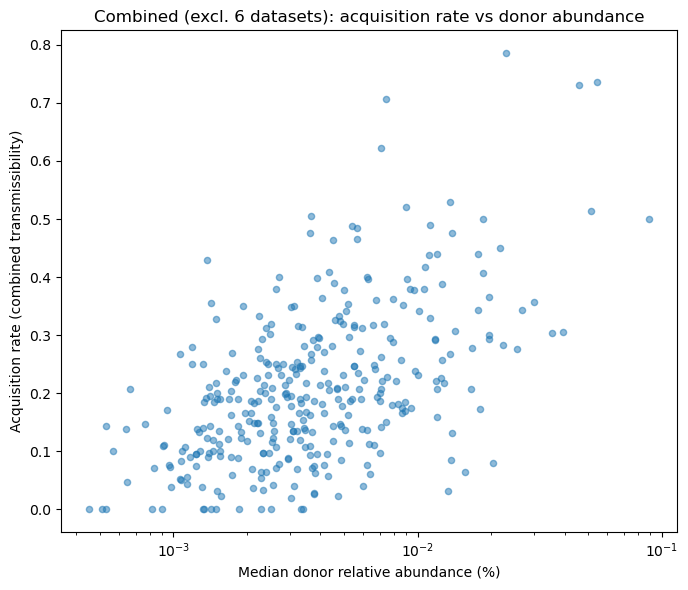


Spearman correlation (combined, excl. datasets): rho=0.504, p=1.22e-23


In [11]:
# ── Flatten the metaphlan multi-index columns down to sample IDs ────────────
# header=[0,1] gives a 2-level column index (sample_id, <constant second level>)
# we only need the sample_id level for lookups
df_metaphlan = df_metaphlan_full.copy()
df_metaphlan.columns = df_metaphlan.columns.get_level_values(1)

# sgb_to_tax already maps 't__SGBxxxx' -> full taxonomy string (the row index
# in df_metaphlan_full). We'll use that to pull abundances.

# ── Collect donor abundances per SGB, split by dataset ──────────────────────
print("\nCollecting donor relative abundances by dataset...")

# NOTE: assumes a 'donor_id' column in sgb_details giving the donor sample ID
# that matches a column name in df_metaphlan. Adjust if your column is named
# differently (e.g. 'donor_fmt_id', 'donor_sample').
donor_id_col = 'donor_id'

sgb_abundance_by_dataset = {}  # dataset -> sgb -> list of donor abundances

for dataset in sgb_details['display_dataset'].dropna().unique():
    dataset_data = sgb_details[sgb_details['display_dataset'] == dataset]
    sgb_abundance_by_dataset.setdefault(dataset, {})

    for _, row in dataset_data.iterrows():
        donor_sample = row[donor_id_col]
        donor_sgbs_str = row['donor_sgbs']

        if pd.isna(donor_sgbs_str) or donor_sgbs_str == '' or pd.isna(donor_sample):
            continue
        if donor_sample not in df_metaphlan.columns:
            continue

        for sgb in set(donor_sgbs_str.split(',')):
            tax_str = sgb_to_tax.get(sgb)
            if tax_str is None or tax_str not in df_metaphlan.index:
                continue
            abundance = df_metaphlan.loc[tax_str, donor_sample]
            sgb_abundance_by_dataset[dataset].setdefault(sgb, []).append(abundance)

# ── Median donor abundance per SGB, per dataset ──────────────────────────────
abundance_rows = []
for dataset, sgb_dict in sgb_abundance_by_dataset.items():
    for sgb, vals in sgb_dict.items():
        abundance_rows.append({
            'display_dataset': dataset,
            'sgb': sgb,
            'median_donor_abundance': np.median(vals),
            'n_donor_samples': len(vals)
        })

abundance_by_dataset_df = pd.DataFrame(abundance_rows)
abundance_by_dataset_df.to_csv('sgb_donor_abundance_by_dataset.csv', index=False)
print(f"Saved per-dataset donor abundances -> sgb_donor_abundance_by_dataset.csv "
      f"({len(abundance_by_dataset_df)} rows)")

# Merge into per-dataset transmissibility table
# Remove abundance columns first in case this cell has been run previously
transmissibility_df = transmissibility_df.drop(
    columns=['median_donor_abundance', 'n_donor_samples'],
    errors='ignore'
)

transmissibility_df = transmissibility_df.merge(
    abundance_by_dataset_df[
        ['display_dataset', 'sgb', 'median_donor_abundance', 'n_donor_samples']
    ],
    on=['display_dataset', 'sgb'],
    how='left'
)
transmissibility_df.to_csv('sgb_transmissibility_by_dataset.csv', index=False)

datasets_to_exclude = ['NgS_2021', 'ShekarrizS_2025', 'CM_MORELIA', 'LeongK_2020',
                        'KousgaardS_2024', 'QuraishiMN_2026']

# Filtered copy used only for the combined (cross-dataset) analysis
sgb_details_combined = sgb_details[~sgb_details['display_dataset'].isin(datasets_to_exclude)].copy()

print(f"Excluded {len(sgb_details) - len(sgb_details_combined)} rows from combined analysis "
      f"({sgb_details['display_dataset'].isin(datasets_to_exclude).sum()} matched exclusion list)")
print(f"Remaining datasets: {sorted(sgb_details_combined['display_dataset'].dropna().unique())}")
# ── Exclude datasets from COMBINED analysis only ─────────────────────────────
datasets_to_exclude = ['NgS_2021', 'ShekarrizS_2025', 'CM_MORELIA', 'LeongK_2020',
                        'KousgaardS_2024', 'QuraishiMN_2026']

sgb_details_combined = sgb_details[~sgb_details['display_dataset'].isin(datasets_to_exclude)].copy()

print(f"Excluded {sgb_details['display_dataset'].isin(datasets_to_exclude).sum()} rows from combined analysis")
print(f"Remaining datasets: {sorted(sgb_details_combined['display_dataset'].dropna().unique())}")

print("\nCalculating COMBINED transmissibility across datasets...")
# Track global counts
global_sgb_in_donor = {}   # sgb -> set of post_fmt_ids
global_sgb_shared = {}     # sgb -> set of post_fmt_ids
sgb_datasets = {}          # sgb -> set of datasets where observed

for _, row in sgb_details_combined.dropna(subset=['display_dataset']).iterrows():
    post_id = row['post_fmt_id']
    dataset = row['display_dataset']
    donor_sgbs_str = row['donor_sgbs']
    shared_sgbs_str = row['shared_donor_post_sgbs']
    if pd.notna(donor_sgbs_str) and donor_sgbs_str != '':
        donor_sgbs = set(donor_sgbs_str.split(','))
        for sgb in donor_sgbs:
            global_sgb_in_donor.setdefault(sgb, set()).add(post_id)
            sgb_datasets.setdefault(sgb, set()).add(dataset)
    if pd.notna(shared_sgbs_str) and shared_sgbs_str != '':
        shared_sgbs = set(shared_sgbs_str.split(','))
        for sgb in shared_sgbs:
            global_sgb_shared.setdefault(sgb, set()).add(post_id)

# Build combined results
combined_results = []
for sgb in global_sgb_in_donor.keys():
    n_opportunities = len(global_sgb_in_donor[sgb])
    n_shared = len(global_sgb_shared.get(sgb, set()))
    n_datasets = len(sgb_datasets.get(sgb, set()))
    # Apply filters
    if n_datasets >= 5 and n_opportunities >= 20:
        transmissibility = n_shared / n_opportunities
        combined_results.append({
            'sgb': sgb,
            'n_datasets_present': n_datasets,
            'n_recipients_with_donor_sgb': n_opportunities,
            'n_recipients_shared': n_shared,
            'combined_transmissibility': transmissibility
        })

combined_df = pd.DataFrame(combined_results)
print(f"Filtered combined SGBs: {len(combined_df)}")
print(f"Mean combined transmissibility: {combined_df['combined_transmissibility'].mean():.4f}")
combined_df = combined_df.sort_values('combined_transmissibility', ascending=False)
combined_df.to_csv('sgb_transmissibility_combined_filtered.csv', index=False)
print("Saved to 'sgb_transmissibility_combined_filtered.csv'")

# ── Taxonomy annotation ───────────────────────────────────────────────────────
combined_df_annotated = combined_df.merge(tax_df, on='sgb', how='left')
combined_df_annotated = combined_df_annotated[[
    'sgb', 'phylum', 'family', 'genus',
    'n_datasets_present', 'n_recipients_with_donor_sgb',
    'n_recipients_shared', 'combined_transmissibility'
]]

# ── Combined (across-dataset) median donor abundance, respecting exclusion ──
global_sgb_abundance = {}  # sgb -> list of all donor abundances (pooled, excluding datasets_to_exclude)
for dataset, sgb_dict in sgb_abundance_by_dataset.items():
    if dataset in datasets_to_exclude:
        continue
    for sgb, vals in sgb_dict.items():
        global_sgb_abundance.setdefault(sgb, []).extend(vals)

combined_abundance_rows = [
    {'sgb': sgb, 'median_donor_abundance': np.median(vals), 'n_donor_samples': len(vals)}
    for sgb, vals in global_sgb_abundance.items()
]
combined_abundance_df = pd.DataFrame(combined_abundance_rows)
combined_abundance_df.to_csv('sgb_donor_abundance_combined.csv', index=False)
print(f"Saved combined donor abundances -> sgb_donor_abundance_combined.csv "
      f"({len(combined_abundance_df)} rows)")

# Merge abundance into combined transmissibility table
combined_df_annotated = combined_df_annotated.merge(
    combined_abundance_df[['sgb', 'median_donor_abundance', 'n_donor_samples']],
    on='sgb',
    how='left'
)
combined_df_annotated.to_csv("sgb_transmissibility_annotated.tsv", sep="\t", index=False)
print("Saved 'sgb_transmissibility_annotated.tsv'")
print(combined_df_annotated.head(10))

# ── Plot: median donor abundance vs acquisition rate (combined, excl. datasets) ─
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

fig, ax = plt.subplots(figsize=(7, 6))
plot_df = combined_df_annotated.dropna(subset=['median_donor_abundance', 'combined_transmissibility'])
ax.scatter(plot_df['median_donor_abundance'], plot_df['combined_transmissibility'], alpha=0.5, s=20)
ax.set_xscale('log')
ax.set_xlabel('Median donor relative abundance (%)')
ax.set_ylabel('Acquisition rate (combined transmissibility)')
ax.set_title(f'Combined (excl. {len(datasets_to_exclude)} datasets): acquisition rate vs donor abundance')
plt.tight_layout()
plt.savefig('donor_abundance_vs_transmissibility_excl.png', dpi=150, bbox_inches='tight')
plt.show()

rho, pval = spearmanr(plot_df['median_donor_abundance'], plot_df['combined_transmissibility'])
print(f"\nSpearman correlation (combined, excl. datasets): rho={rho:.3f}, p={pval:.2e}")

Excluded 0 rows from multi-donor datasets, plus 0 multi-donor rows from PorcariS_2026 (491 rows remaining)
Built 33976 (donor-recipient, rank) observations from 484 recipients
Of 8092 donor-post shared observations, 201 were also shared at baseline (pre-FMT) and are NOT counted as acquisition

Transmissibility by within-donor abundance rank:
 abundance_rank  n_opportunities  n_shared  transmissibility
              1              491       197          0.401222
              2              491       183          0.372709
              3              491       174          0.354379
              4              491       195          0.397149
              5              491       154          0.313646
              6              491       173          0.352342
              7              491       158          0.321792
              8              491       159          0.323829
              9              491       162          0.329939
             10              491       162    

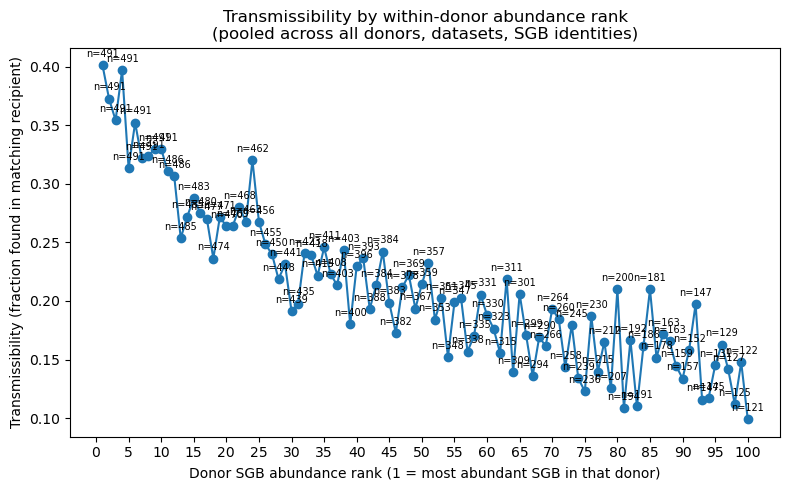


ABUNDANCE FLOOR FOR ENGRAFTMENT

Donor abundance distribution, acquired (True) vs not (False):
            count      mean       std       min       25%       50%       75%  \
acquired                                                                        
False     26085.0  0.011481  0.022916  0.000289  0.002161  0.004563  0.011305   
True       7891.0  0.018760  0.037808  0.000274  0.002941  0.006973  0.018467   

               max  
acquired            
False     0.632347  
True      0.563122  

Lowest donor abundance with observed acquisition: 0.0002741% (SGB t__SGB15117, rank 78, dataset NooijS_2024, donor ERR11834500, recipient ERR11836863)
Highest donor abundance WITHOUT engraftment: 0.632347% (SGB t__SGB1871, rank 1, dataset DavarD_2021, donor SAMN16673231, recipient SAMN16673227)

No rank (with n_opportunities >= 10) had 0% transmissibility.


In [12]:
"""
Quick test: transmissibility by ABUNDANCE RANK within each donor sample, irrespective
of dataset or SGB identity.

For every donor sample, rank the SGBs it carries by relative abundance (rank 1 = the
single most abundant SGB in that donor, rank 2 = second most abundant, etc.) -- ranked
only against the OTHER SGBs in that same donor's own profile, nothing else.

Then, pooling across every donor-recipient pair in the whole cohort (all datasets,
all donors, all SGB identities thrown together), ask: of all the "rank 1" SGBs
(the most abundant SGB in each donor), what fraction turned up in the matching
recipient? Same question for rank 2, rank 3, ...

Requires (from the main pipeline): sgb_details (with display_dataset merged in,
LUMINATE excluded), df_metaphlan, sgb_to_tax.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DONOR_ID_COL = 'donor_id'
MAX_RANK = 100           # only look at the top-N most abundant (strain-profiled) SGBs per donor
MIN_OPPORTUNITIES = 10   # only plot/report ranks backed by at least this many donor observations

# multi-donor datasets: excluded outright because a single recipient can have more
# than one donor, which breaks the "one donor's ranked profile -> one recipient"
# comparison this analysis assumes
DATASETS_TO_EXCLUDE = ['NgS_2021', 'ShekarrizS_2025', 'CM_MORELIA', 'LeongK_2020',
                        'KousgaardS_2024', 'QuraishiMN_2026']

# PorcariS_2026 is otherwise single-donor, EXCEPT for these specific (dataset, pre_fmt_id)
# pairs, which are multi-donor recipients within that dataset -- drop only those rows
# rather than the whole dataset.
# NOTE: this list looked truncated (ends mid-entry, no closing bracket) in what was
# pasted -- double check it's complete before running.
placebo_pairs = [
    ('PorcariS_2026', 'FMT_T003_t0'), ('PorcariS_2026', 'FMT_T006_t0'),
    ('PorcariS_2026', 'FMT_T008_t0'), ('PorcariS_2026', 'FMT_T012_t0'),
    ('PorcariS_2026', 'FMT_T014_t0'), ('PorcariS_2026', 'FMT_T016_t0'),
    ('PorcariS_2026', 'FMT_T018_t0'), ('PorcariS_2026', 'FMT_T020_t0'),
    ('PorcariS_2026', 'FMT_T021_t0'), ('PorcariS_2026', 'FMT_T025_t0'),
    ('PorcariS_2026', 'FMT_T028_t0'), ('PorcariS_2026', 'FMT_T029_t0'),
    ('PorcariS_2026', 'FMT_T034_t0'), ('PorcariS_2026', 'FMT_T035_t0'),
    ('PorcariS_2026', 'FMT_T037_t0'), ('PorcariS_2026', 'FMT_T040_t0'),
    ('PorcariS_2026', 'FMT_T042_t0'), ('PorcariS_2026', 'FMT_T046_t0'),
    ('PorcariS_2026', 'FMT_T047_t0'), ('PorcariS_2026', 'FMT_T051_t0'),
    ('PorcariS_2026', 'FMT_T052_t0'), ('PorcariS_2026', 'FMT_T053_t0'),
    ('PorcariS_2026', 'FMT_T054_t0'), ('PorcariS_2026', 'FMT_T002_t0'),
]

# ============================================================
# 1. Build one row per (donor-recipient pair, abundance rank)
# ============================================================
sgb_details_filtered = sgb_details[~sgb_details['display_dataset'].isin(DATASETS_TO_EXCLUDE)].copy()
n_dataset_excluded = sgb_details['display_dataset'].isin(DATASETS_TO_EXCLUDE).sum()

is_placebo_pair = sgb_details_filtered.apply(
    lambda r: (r['display_dataset'], r['pre_fmt_id']) in placebo_pairs, axis=1
)
n_pair_excluded = is_placebo_pair.sum()
sgb_details_filtered = sgb_details_filtered[~is_placebo_pair].copy()

print(f"Excluded {n_dataset_excluded} rows from multi-donor datasets, "
      f"plus {n_pair_excluded} multi-donor rows from PorcariS_2026 "
      f"({len(sgb_details_filtered)} rows remaining)")

rank_rows = []
for _, row in sgb_details_filtered.iterrows():
    donor_sample = row.get(DONOR_ID_COL)
    donor_sgbs_str = row['donor_sgbs']
    shared_post_str = row['shared_donor_post_sgbs']
    shared_pre_str = row['shared_donor_pre_sgbs']

    if pd.isna(donor_sgbs_str) or donor_sgbs_str == '' or pd.isna(donor_sample):
        continue
    if donor_sample not in df_metaphlan.columns:
        continue

    donor_sgbs = set(donor_sgbs_str.split(','))
    shared_post_sgbs = (set(shared_post_str.split(','))
                        if pd.notna(shared_post_str) and shared_post_str != '' else set())
    shared_pre_sgbs = (set(shared_pre_str.split(','))
                       if pd.notna(shared_pre_str) and shared_pre_str != '' else set())

    # This donor's own abundance for each SGB it carries. Only SGBs that appear in
    # donor_sgbs are considered -- donor_sgbs contains only strain-level-profiled
    # SGBs (as built in sgb_details), so this already excludes any SGB that has a
    # MetaPhlAn abundance value but wasn't successfully profiled at the strain
    # level. We do NOT rank against the full MetaPhlAn abundance table for this
    # donor sample -- only against this strain-profiled subset.
    abund = []
    for sgb in donor_sgbs:
        tax_str = sgb_to_tax.get(sgb)
        if tax_str is None or tax_str not in df_metaphlan.index:
            continue
        abund.append((sgb, df_metaphlan.loc[tax_str, donor_sample]))

    if not abund:
        continue

    # rank 1 = most abundant SGB in THIS donor sample (ties broken by list order)
    abund.sort(key=lambda x: x[1], reverse=True)

    for rank, (sgb, ab) in enumerate(abund[:MAX_RANK], start=1):
        rank_rows.append({
            'post_fmt_id': row['post_fmt_id'],
            'donor_id': donor_sample,
            'display_dataset': row.get('display_dataset'),
            'abundance_rank': rank,
            'sgb': sgb,
            'abundance': ab,
            # shared_post: SGB found in donor and post-FMT recipient sample
            # shared_pre: SGB was ALSO already shared with donor pre-FMT -- i.e. the
            #   recipient already carried this strain at baseline, so its presence
            #   post-FMT is not acquisition, just persistence of what was already there
            # acquired: true acquisition -- present post-FMT AND NOT already present pre-FMT
            'shared_post': sgb in shared_post_sgbs,
            'shared_pre': sgb in shared_pre_sgbs,
            'acquired': (sgb in shared_post_sgbs) and (sgb not in shared_pre_sgbs),
        })

rank_df = pd.DataFrame(rank_rows)
rank_df.to_csv('sgb_abundance_rank_transmissibility_raw.csv', index=False)
print(f"Built {len(rank_df)} (donor-recipient, rank) observations "
      f"from {rank_df['post_fmt_id'].nunique()} recipients")

n_baseline_shared = ((rank_df['shared_post']) & (rank_df['shared_pre'])).sum()
print(f"Of {rank_df['shared_post'].sum()} donor-post shared observations, "
      f"{n_baseline_shared} were also shared at baseline (pre-FMT) and are "
      f"NOT counted as acquisition")

# ============================================================
# 2. Pool across ALL donors/datasets/SGB identities: transmissibility per rank
# ============================================================
rank_summary = (
    rank_df.groupby('abundance_rank')
    .agg(n_opportunities=('acquired', 'count'), n_shared=('acquired', 'sum'))
    .reset_index()
)
rank_summary['transmissibility'] = rank_summary['n_shared'] / rank_summary['n_opportunities']
rank_summary.to_csv('sgb_transmissibility_by_abundance_rank.csv', index=False)
print("\nTransmissibility by within-donor abundance rank:")
print(rank_summary.to_string(index=False))

# ============================================================
# 3. Plot
# ============================================================
plot_df = rank_summary[rank_summary['n_opportunities'] >= MIN_OPPORTUNITIES]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(plot_df['abundance_rank'], plot_df['transmissibility'], marker='o')
ax.set_xlabel('Donor SGB abundance rank (1 = most abundant SGB in that donor)')
ax.set_ylabel('Transmissibility (fraction found in matching recipient)')
ax.set_title('Transmissibility by within-donor abundance rank\n(pooled across all donors, datasets, SGB identities)')
ax.set_xticks(range(0, plot_df['abundance_rank'].max() + 1, 5))
for _, r in plot_df.iterrows():
    ax.annotate(f"n={int(r['n_opportunities'])}",
                (r['abundance_rank'], r['transmissibility']),
                textcoords="offset points", xytext=(0, 6), fontsize=7, ha='center')
plt.tight_layout()
plt.savefig('transmissibility_by_abundance_rank.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# 4. Abundance floor for engraftment
# ============================================================
# Two complementary views:
#   (a) the single lowest donor abundance at which engraftment was STILL observed
#       -- the empirical floor, useful as a one-number manuscript statement
#   (b) the abundance range covered by observations at ranks where transmissibility
#       was exactly 0% -- shows what abundance range is associated with failure

print("\n" + "=" * 60)
print("ABUNDANCE FLOOR FOR ENGRAFTMENT")
print("=" * 60)

# (a) overall abundance distributions, engrafted vs not
abund_by_outcome = rank_df.groupby('acquired')['abundance'].describe()
print("\nDonor abundance distribution, acquired (True) vs not (False):")
print(abund_by_outcome)

# lowest abundance among observations that DID show true acquisition
engrafted = rank_df[rank_df['acquired']]
if len(engrafted) > 0:
    floor_row = engrafted.loc[engrafted['abundance'].idxmin()]
    print(f"\nLowest donor abundance with observed acquisition: "
          f"{floor_row['abundance']:.6g}% "
          f"(SGB {floor_row['sgb']}, rank {floor_row['abundance_rank']}, "
          f"dataset {floor_row['display_dataset']}, donor {floor_row['donor_id']}, "
          f"recipient {floor_row['post_fmt_id']})")
else:
    print("\nNo acquisition observed in this filtered dataset.")

# for context: highest abundance among observations that did NOT show acquisition
# (a large value here means high abundance alone doesn't guarantee acquisition)
not_engrafted = rank_df[~rank_df['acquired']]
if len(not_engrafted) > 0:
    ceiling_row = not_engrafted.loc[not_engrafted['abundance'].idxmax()]
    print(f"Highest donor abundance WITHOUT engraftment: "
          f"{ceiling_row['abundance']:.6g}% "
          f"(SGB {ceiling_row['sgb']}, rank {ceiling_row['abundance_rank']}, "
          f"dataset {ceiling_row['display_dataset']}, donor {ceiling_row['donor_id']}, "
          f"recipient {ceiling_row['post_fmt_id']})")

# (b) ranks where transmissibility was exactly 0 (restricted to well-sampled ranks)
zero_ranks = rank_summary[
    (rank_summary['transmissibility'] == 0) & (rank_summary['n_opportunities'] >= MIN_OPPORTUNITIES)
]
if len(zero_ranks) > 0:
    zero_rank_obs = rank_df[rank_df['abundance_rank'].isin(zero_ranks['abundance_rank'])]
    print(f"\nRanks with 0% transmissibility (n_opportunities >= {MIN_OPPORTUNITIES}): "
          f"{sorted(zero_ranks['abundance_rank'].tolist())}")
    print(f"Abundance range across observations at those ranks: "
          f"{zero_rank_obs['abundance'].min():.6g}% - {zero_rank_obs['abundance'].max():.6g}% "
          f"(median {zero_rank_obs['abundance'].median():.6g}%, n={len(zero_rank_obs)})")
else:
    print(f"\nNo rank (with n_opportunities >= {MIN_OPPORTUNITIES}) had 0% transmissibility.")

# Save the underlying observations for both flagged groups for manuscript reference
engrafted.nsmallest(20, 'abundance').to_csv('lowest_abundance_engrafted_examples.csv', index=False)
if len(zero_ranks) > 0:
    zero_rank_obs.to_csv('zero_transmissibility_rank_observations.csv', index=False)

Fit: transmissibility = 0.1887 * log10(abundance) + 0.6683
R-squared: 0.3006

SGBs with residuals computed: 345 / 345

Top 15 SGBs MORE transmissible than abundance predicts:
              sgb                     genus  median_donor_abundance  combined_transmissibility  predicted_transmissibility  residual
       t__SGB2071                   GGB1495                0.007405                   0.707317                    0.266205  0.441113
       t__SGB5818                 Dialister                0.022952                   0.785714                    0.358919  0.426796
       t__SGB6783           Catenibacterium                0.007115                   0.622642                    0.262928  0.359713
       t__SGB1679                   Leyella                0.046036                   0.730769                    0.415966  0.314804
       t__SGB1613                 Segatella                0.054197                   0.735294                    0.429343  0.305951
       t__SGB5060          

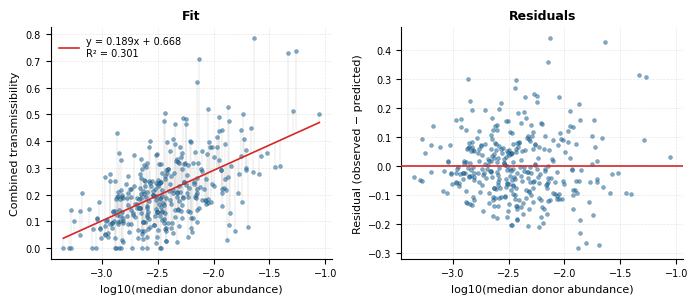

In [13]:
from scipy import stats
import numpy as np

# ── Residual analysis: transmissibility vs log10(donor abundance) ───────────
resid_df = combined_df_annotated.dropna(subset=['median_donor_abundance', 'combined_transmissibility']).copy()

# log-transform abundance (add small pseudocount in case of zeros)
resid_df['log10_abundance'] = np.log10(resid_df['median_donor_abundance'] + 1e-6)

# Fit linear regression: transmissibility ~ log10(abundance)
slope, intercept, r_value, p_value, std_err = stats.linregress(
    resid_df['log10_abundance'], resid_df['combined_transmissibility']
)
print(f"Fit: transmissibility = {slope:.4f} * log10(abundance) + {intercept:.4f}")
print(f"R-squared: {r_value**2:.4f}")

# Predicted transmissibility given abundance, and residual (observed - predicted)
resid_df['predicted_transmissibility'] = slope * resid_df['log10_abundance'] + intercept
resid_df['residual'] = resid_df['combined_transmissibility'] - resid_df['predicted_transmissibility']

# ── Merge the new columns back into the main annotated table ────────────────
# (drop first, in case this cell is re-run)
for col in ['log10_abundance', 'predicted_transmissibility', 'residual']:
    if col in combined_df_annotated.columns:
        combined_df_annotated = combined_df_annotated.drop(columns=col)

combined_df_annotated = combined_df_annotated.merge(
    resid_df[['sgb', 'log10_abundance', 'predicted_transmissibility', 'residual']],
    on='sgb',
    how='left'
)
print(f"\nSGBs with residuals computed: {combined_df_annotated['residual'].notna().sum()} / {len(combined_df_annotated)}")

# Rank: highest positive residual = more transmissible than abundance predicts
resid_df_sorted = resid_df.sort_values('residual', ascending=False)
print("\nTop 15 SGBs MORE transmissible than abundance predicts:")
print(resid_df_sorted[['sgb', 'genus', 'median_donor_abundance', 'combined_transmissibility',
                        'predicted_transmissibility', 'residual']].head(15).to_string(index=False))
print("\nTop 15 SGBs LESS transmissible than abundance predicts:")
print(resid_df_sorted[['sgb', 'genus', 'median_donor_abundance', 'combined_transmissibility',
                        'predicted_transmissibility', 'residual']].tail(15).to_string(index=False))

# Save full residual table
resid_df_sorted.to_csv('sgb_transmissibility_residuals.csv', index=False)
combined_df_annotated.to_csv("sgb_transmissibility_annotated.tsv", sep="\t", index=False)
print("\nSaved 'sgb_transmissibility_residuals.csv' and updated 'sgb_transmissibility_annotated.tsv'")

import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['svg.fonttype'] = 'none'   # keep text editable in the SVG

x = resid_df['log10_abundance']
y = resid_df['combined_transmissibility']
x_line = np.linspace(x.min(), x.max(), 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(180 / 25.4, 80 / 25.4))

# ── Left: data, fitted line, and residual segments ───────────────────────────
ax1.vlines(x, resid_df['predicted_transmissibility'], y,
           color='#999999', linewidth=0.3, alpha=0.5, zorder=1)
ax1.scatter(x, y, s=8, color='#1f77b4', edgecolors='k',
            linewidths=0.2, alpha=0.6, zorder=2)
ax1.plot(x_line, slope * x_line + intercept, color='#d62728', linewidth=1.2,
         zorder=3, label=f'y = {slope:.3f}x + {intercept:.3f}\nR² = {r_value**2:.3f}')
ax1.set_xlabel('log10(median donor abundance)', fontsize=8)
ax1.set_ylabel('Combined transmissibility', fontsize=8)
ax1.set_title('Fit', fontsize=9, fontweight='bold')
ax1.legend(fontsize=7, frameon=False, loc='best')

# ── Right: residuals vs abundance ────────────────────────────────────────────
ax2.scatter(x, resid_df['residual'], s=8, color='#1f77b4', edgecolors='k',
            linewidths=0.2, alpha=0.6, zorder=2)
ax2.axhline(0, color='#d62728', linewidth=1.2, zorder=3)
ax2.set_xlabel('log10(median donor abundance)', fontsize=8)
ax2.set_ylabel('Residual (observed − predicted)', fontsize=8)
ax2.set_title('Residuals', fontsize=9, fontweight='bold')

for ax in (ax1, ax2):
    ax.tick_params(labelsize=7)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.3, linestyle='--', linewidth=0.5)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('transmissibility_vs_abundance_residuals.svg')
plt.show()

Plot order: ['Bacteroidota', 'Actinomycetota', 'Pseudomonadota', 'Firmicutes']

Group medians (n, median, Q1, Q3):
                  n  median      q1      q3
phylum                                     
Bacteroidota     47  0.0807  0.0213  0.1520
Actinomycetota   14  0.0770  0.0272  0.1965
Pseudomonadota   10  0.0376 -0.0585  0.1586
Firmicutes      267 -0.0250 -0.0915  0.0425

Kruskal-Wallis: H = 49.945, P = 8.21e-11

Dunn test FDR-corrected p-values:
        group1         group2         pval     pval_fdr
    Firmicutes   Bacteroidota 1.247718e-09 7.486311e-09
    Firmicutes Actinomycetota 7.158050e-05 2.147415e-04
    Firmicutes Pseudomonadota 1.074843e-01 2.149685e-01
  Bacteroidota Pseudomonadota 2.040007e-01 2.448009e-01
Actinomycetota Pseudomonadota 1.683801e-01 2.448009e-01
  Bacteroidota Actinomycetota 6.743111e-01 6.743111e-01


/tmp/ipykernel_765507/8183583.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


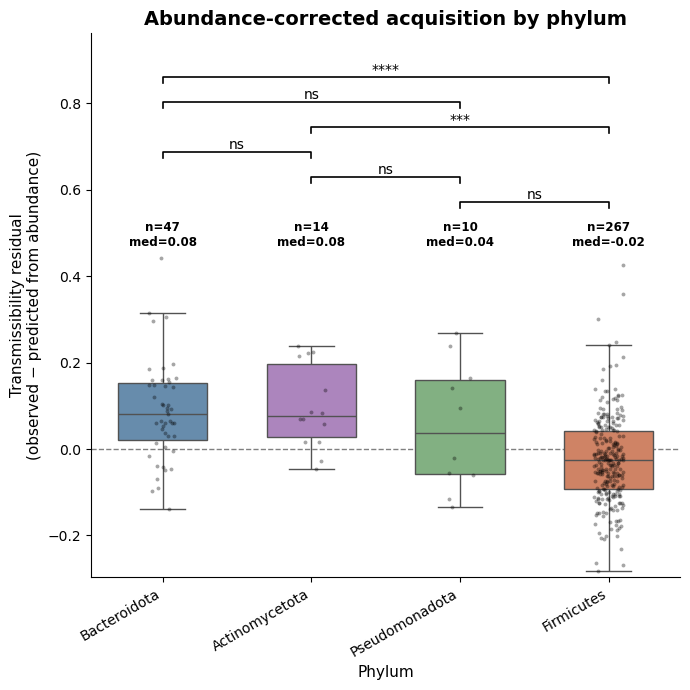

In [14]:
from scipy.stats import kruskal, rankdata, norm
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def dunn_test(df, val_col, group_col, p_adjust='fdr_bh'):
    """Manual Dunn's test with BH correction, no scikit-posthocs needed."""
    groups = df[group_col].unique()
    n_total = len(df)

    df = df.copy()
    df['rank'] = rankdata(df[val_col])

    mean_ranks = df.groupby(group_col)['rank'].mean()
    group_sizes = df.groupby(group_col)['rank'].count()

    # Tie correction factor (computed from tie counts, not group sizes)
    _, tie_counts = np.unique(df[val_col].values, return_counts=True)
    tie_correction = 1 - (tie_counts ** 3 - tie_counts).sum() / (n_total ** 3 - n_total)

    pairs, pvals = [], []
    for g1, g2 in combinations(groups, 2):
        n1, n2 = group_sizes[g1], group_sizes[g2]
        se = np.sqrt(tie_correction * (n_total * (n_total + 1) / 12) * (1/n1 + 1/n2))
        z = abs(mean_ranks[g1] - mean_ranks[g2]) / se
        p = 2 * norm.sf(z)
        pairs.append((g1, g2))
        pvals.append(p)

    _, pvals_corrected, _, _ = multipletests(pvals, method=p_adjust)

    results = pd.DataFrame([
        {'group1': g1, 'group2': g2, 'pval': p, 'pval_fdr': pfdr}
        for (g1, g2), p, pfdr in zip(pairs, pvals, pvals_corrected)
    ]).sort_values('pval_fdr')

    return results


# ── 1. Drop rows with missing phylum or residual ───────────────────────────
df_test = combined_df_annotated.dropna(subset=['phylum', 'residual'])

min_n = 5
phylum_counts = df_test['phylum'].value_counts()
valid_phyla = phylum_counts[phylum_counts >= min_n].index
df_test = df_test[df_test['phylum'].isin(valid_phyla)]

medians = df_test.groupby('phylum')['residual'].median().sort_values(ascending=False)
order = medians.index.tolist()
print("Plot order:", order)

# ── Group summary (n, median, IQR) ────────────────────────────────────────────
summary = (
    df_test.groupby('phylum')['residual']
    .agg(n='count',
         median='median',
         q1=lambda x: x.quantile(0.25),
         q3=lambda x: x.quantile(0.75))
    .reindex(order)
)
print("\nGroup medians (n, median, Q1, Q3):")
print(summary.round(4).to_string())
summary.to_csv("phylum_residual_summary.tsv", sep="\t")

# ── 2. Kruskal-Wallis ─────────────────────────────────────────────────────────
groups = [grp['residual'].values for _, grp in df_test.groupby('phylum')]
kw_stat, kw_p = kruskal(*groups)
print(f"\nKruskal-Wallis: H = {kw_stat:.3f}, P = {kw_p:.2e}")

# ── 3. Dunn test ──────────────────────────────────────────────────────────────
dunn_results = dunn_test(df_test, val_col='residual', group_col='phylum')
print("\nDunn test FDR-corrected p-values:")
print(dunn_results.to_string(index=False))
dunn_results.to_csv("dunn_phylum_residual.tsv", sep="\t", index=False)

# ── Phylum colors ────────────────────────────────────────────────────────────
phylum_palette = {
    'Firmicutes': '#e07b54',
    'Bacteroidota': '#5b8db8',
    'Pseudomonadota': '#7ab87a',
    'Proteobacteria': '#7ab87a',
    'Actinomycetota': '#b07cc6',
    'Actinobacteria': '#b07cc6',
}
palette = [phylum_palette.get(p, "#cccccc") for p in order]

def p_to_asterisk(p):
    if p < 0.0001: return '****'
    elif p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

# ── Figure ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 7))

sns.boxplot(
    data=df_test, x='phylum', y='residual', order=order,
    palette=palette, width=0.6, showfliers=False, ax=ax
)
sns.stripplot(
    data=df_test, x='phylum', y='residual', order=order,
    color='black', alpha=0.35, size=2.8, jitter=True, ax=ax
)

ax.axhline(0, color='gray', lw=1, linestyle='--', zorder=0)

# ── n and median annotations ──────────────────────────────────────────────────
y_max = df_test['residual'].max()
y_min = df_test['residual'].min()
y_range = y_max - y_min

for i, phylum in enumerate(order):
    n = int(summary.loc[phylum, 'n'])
    med = summary.loc[phylum, 'median']
    ax.text(i, y_max + 0.03 * y_range, f"n={n}\nmed={med:.2f}",
            ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# ── Significance bars ─────────────────────────────────────────────────────────
pos = {p: i for i, p in enumerate(order)}
sig_pairs = dunn_results[
    dunn_results['group1'].isin(order) & dunn_results['group2'].isin(order)
].copy()
sig_pairs['x1'] = sig_pairs['group1'].map(pos)
sig_pairs['x2'] = sig_pairs['group2'].map(pos)
sig_pairs['dist'] = (sig_pairs['x1'] - sig_pairs['x2']).abs()
sig_pairs = sig_pairs.sort_values('dist')

# start bars higher to leave room for the two-line n/median labels
bar_start = y_max + 0.16 * y_range
step = 0.08 * y_range

for j, (_, row) in enumerate(sig_pairs.iterrows()):
    x1, x2 = sorted([row['x1'], row['x2']])
    y = bar_start + j * step
    label = p_to_asterisk(row['pval_fdr'])
    ax.plot([x1, x1, x2, x2], [y, y + step*0.25, y + step*0.25, y], lw=1.2, color='black')
    ax.text((x1 + x2) / 2, y + step*0.25, label, ha='center', va='bottom', fontsize=10)

top_y = bar_start + len(sig_pairs) * step + step
ax.set_ylim(y_min - 0.02 * y_range, top_y)

ax.set_title("Abundance-corrected acquisition by phylum", fontsize=14, fontweight='bold')
ax.set_xlabel("Phylum", fontsize=11)
ax.set_ylabel("Transmissibility residual\n(observed − predicted from abundance)", fontsize=11)
ax.tick_params(axis='x', rotation=30)
plt.setp(ax.get_xticklabels(), ha='right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("acquisition_residual_by_phylum.png", dpi=300)
plt.show()

 level         H            p     eta2       R2   n  k
phylum 49.945033 8.207452e-11 0.140554 0.155332 338  4
family 65.118280 6.274629e-09 0.218984 0.310396 252 14
 genus 70.153127 1.810668e-09 0.492571 0.530614 129 15

Nested model comparison:
   df_resid       ssr  df_diff   ss_diff         F    Pr(>F)
0     126.0  0.824948      0.0       NaN       NaN       NaN
1     122.0  0.701578      4.0  0.123369  6.822667  0.000055
2     114.0  0.515345      8.0  0.186233  5.149607  0.000017

R² phylum only:            0.249
R² phylum + family:        0.361
R² phylum + family + genus:0.531


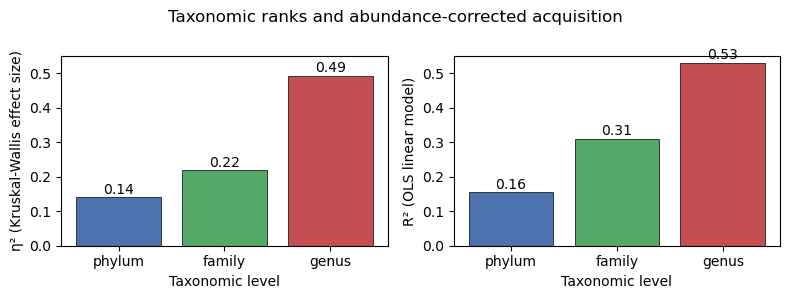

In [15]:
from sklearn.preprocessing import LabelEncoder
import statsmodels.formula.api as smf
from scipy.stats import kruskal

# ── How much variance is explained at each taxonomic level? ──────────────────
results = []
for level in ['phylum', 'family', 'genus']:
    df_lvl = combined_df_annotated.dropna(subset=[level, 'residual'])
    counts = df_lvl[level].value_counts()
    df_lvl = df_lvl[df_lvl[level].isin(counts[counts >= min_n].index)]

    groups = [g['residual'].values for _, g in df_lvl.groupby(level)]
    h, p = kruskal(*groups)
    k = len(groups)
    n = len(df_lvl)
    eta2 = (h - k + 1) / (n - k)

    model = smf.ols(f'residual ~ C({level})', data=df_lvl).fit()
    r2 = model.rsquared

    results.append({'level': level, 'H': h, 'p': p, 'eta2': eta2, 'R2': r2, 'n': n, 'k': k})

variance_df = pd.DataFrame(results)
print(variance_df.to_string(index=False))
variance_df.to_csv("phylo_variance_explained_residual.tsv", sep="\t", index=False)

# ── Nested ANOVA: does genus explain variance beyond phylum/family? ───────────
df_nested = combined_df_annotated.dropna(subset=['phylum', 'family', 'genus', 'residual'])
valid_genera = df_nested['genus'].value_counts()
df_nested = df_nested[df_nested['genus'].isin(valid_genera[valid_genera >= min_n].index)]

m_phylum = smf.ols('residual ~ C(phylum)', data=df_nested).fit()
m_family = smf.ols('residual ~ C(phylum) + C(family)', data=df_nested).fit()
m_genus  = smf.ols('residual ~ C(phylum) + C(family) + C(genus)', data=df_nested).fit()

from statsmodels.stats.anova import anova_lm
nested_anova = anova_lm(m_phylum, m_family, m_genus)
print("\nNested model comparison:")
print(nested_anova)
nested_anova.to_csv("nested_anova_phylo_residual.tsv", sep="\t")

print(f"\nR² phylum only:            {m_phylum.rsquared:.3f}")
print(f"R² phylum + family:        {m_family.rsquared:.3f}")
print(f"R² phylum + family + genus:{m_genus.rsquared:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, metric, label in zip(axes, ['eta2', 'R2'], ['η² (Kruskal-Wallis effect size)', 'R² (OLS linear model)']):
    ax.bar(variance_df['level'], variance_df[metric], color=['#4C72B0','#55A868','#C44E52'],
           edgecolor='black', linewidth=0.5)
    ax.set_ylim(0, 0.55)
    ax.set_ylabel(label)
    ax.set_xlabel("Taxonomic level")
    for i, v in enumerate(variance_df[metric]):
        ax.text(i, v + 0.01, f"{v:.2f}", ha='center', fontsize=10)
fig.suptitle("Taxonomic ranks and abundance-corrected acquisition", fontsize=12)
plt.tight_layout()
plt.show()

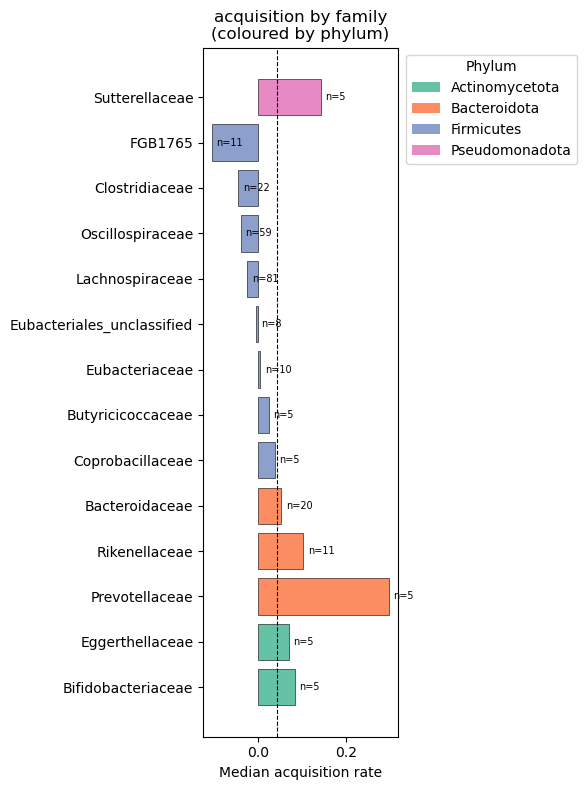

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Median transmissibility per family, annotated with phylum
df_plot = (combined_df_annotated
           .dropna(subset=['phylum', 'family', 'residual'])
           .groupby(['phylum', 'family'])['residual']
           .agg(['median', 'count'])
           .reset_index()
           .query('count >= @min_n')
           .sort_values(['phylum', 'median'], ascending=[True, False]))

fig, ax = plt.subplots(figsize=(6, 8))
colors = sns.color_palette("Set2", df_plot['phylum'].nunique())
phylum_palette = dict(zip(df_plot['phylum'].unique(), colors))
row_colors = df_plot['phylum'].map(phylum_palette)

bars = ax.barh(df_plot['family'], df_plot['median'],
               color=row_colors, edgecolor='black', linewidth=0.4)
# Add n labels to each bar
for bar, n in zip(bars, df_plot['count']):
    ax.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"n={n}",
        va='center',
        fontsize=7,
        color='black'
    )
# Phylum legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=p) for p, c in phylum_palette.items()]
ax.legend(handles=legend_elements, title='Phylum', bbox_to_anchor=(1.01, 1), loc='upper left')

ax.set_xlabel("Median acquisition rate")
ax.set_title("acquisition by family\n(coloured by phylum)")
ax.axvline(df_plot['median'].mean(), color='black', linewidth=0.8, linestyle='--', label='mean')
plt.tight_layout()
# plt.savefig("acquisition_by_family_phylo.png", dpi=150, bbox_inches='tight')
plt.show()

In [17]:
predict = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/f.asnicar/git/zoe/2022__NEW_ANALYSES/proj__ZOE_score/tables/CHM_and_DIET_ranks.tsv', sep='\t')
predict.head()
#use mean_atleast2_CHM

,SGB,P1_CHM,P2_CHM,P3_US21_CHM,P3_US22A_CHM,P3_UK22A_CHM,mean_atleast2_CHM,P1_DIET,P2_DIET,P3_US21_DIET,P3_US22A_DIET,P3_UK22A_DIET,mean_atleast2_DIET
0,SGB10068,0.981395,0.896552,0.981187,0.964968,0.918689,0.948558,0.953488,0.643678,0.904486,0.785032,0.837379,0.824813
1,SGB10115,NaN,NaN,0.943560,NaN,0.932039,0.937799,NaN,NaN,0.596961,NaN,0.865291,0.731126
2,SGB13976,NaN,NaN,0.253256,NaN,0.493932,0.373594,NaN,NaN,0.485528,NaN,0.739684,0.612606
3,SGB13979,NaN,NaN,0.331404,0.133758,0.033981,0.166381,NaN,NaN,0.157742,0.154459,0.336772,0.216324
4,SGB13981,0.297674,0.356322,0.023155,0.014331,0.076456,0.153588,0.358140,0.272989,0.112880,0.242038,0.114078,0.220025


In [18]:
print(predict.columns)

Index(['SGB', 'P1_CHM', 'P2_CHM', 'P3_US21_CHM', 'P3_US22A_CHM',
       'P3_UK22A_CHM', 'mean_atleast2_CHM', 'P1_DIET', 'P2_DIET',
       'P3_US21_DIET', 'P3_US22A_DIET', 'P3_UK22A_DIET', 'mean_atleast2_DIET'],
      dtype='str')


SGBs matched: 250
SGBs with CHM score: 250 / 345
Spearman ρ = 0.183, P = 3.60e-03, n = 250


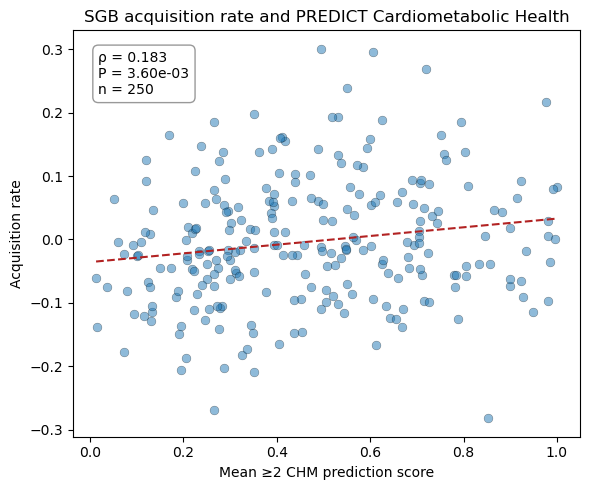

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import numpy as np

# ── Normalize sgb IDs to match (strip 't__' from combined_df_annotated) ──────
df_combined = combined_df_annotated.copy()
df_combined['sgb_key'] = df_combined['sgb'].str.replace('t__', '', regex=False)

# Drop pre-existing CHM column to avoid collision on merge
if 'mean_atleast2_CHM' in df_combined.columns:
    df_combined = df_combined.drop(columns='mean_atleast2_CHM')

predict = predict.copy()
predict['sgb_key'] = predict['SGB']  # already in SGB10115 format

# ── Merge on normalized key ───────────────────────────────────────────────────
df_spearman = df_combined.merge(
    predict[['sgb_key', 'mean_atleast2_CHM']],
    on='sgb_key',
    how='inner'
).dropna(subset=['mean_atleast2_CHM', 'residual'])

print(f"SGBs matched: {len(df_spearman)}")

# ── Append mean_atleast2_CHM back to combined_df_annotated ───────────────────
combined_df_annotated['sgb_key'] = combined_df_annotated['sgb'].str.replace('t__', '', regex=False)

if 'mean_atleast2_CHM' in combined_df_annotated.columns:
    combined_df_annotated = combined_df_annotated.drop(columns='mean_atleast2_CHM')

combined_df_annotated = combined_df_annotated.merge(
    predict[['sgb_key', 'mean_atleast2_CHM']],
    on='sgb_key',
    how='left'
).drop(columns='sgb_key')

# Save updated table
combined_df_annotated.to_csv("sgb_transmissibility_annotated.tsv", sep="\t", index=False)
print(f"SGBs with CHM score: {combined_df_annotated['mean_atleast2_CHM'].notna().sum()} / {len(combined_df_annotated)}")
combined_df_annotated.head()

# ── Spearman correlation ──────────────────────────────────────────────────────
rho, pval = spearmanr(
    df_spearman['mean_atleast2_CHM'],
    df_spearman['residual']
)
n = len(df_spearman)
print(f"Spearman ρ = {rho:.3f}, P = {pval:.2e}, n = {n}")

# ── Scatter plot ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 5))

x = df_spearman['mean_atleast2_CHM']
y = df_spearman['residual']

ax.scatter(
    x, y,
    alpha=0.5,
    edgecolors='k',
    linewidths=0.3,
    s=40
)

# ── Trend line (linear fit) ───────────────────────────────────────────────────
m, b = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
ax.plot(x_line, m * x_line + b, color='firebrick', linewidth=1.5, linestyle='--', label='Linear fit')

# ── Annotate rho and p-value ──────────────────────────────────────────────────
pval_str = f"= {pval:.2e}" if pval >= 1e-300 else "< 1e-300"
ax.text(
    0.05, 0.95,
    f"ρ = {rho:.3f}\nP {pval_str}\nn = {n}",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', alpha=0.8)
)

ax.set_xlabel("Mean ≥2 CHM prediction score")
ax.set_ylabel("Acquisition rate")
ax.set_title("SGB acquisition rate and PREDICT Cardiometabolic Health")
plt.tight_layout()
plt.savefig("CHM_acq_scatter.png", dpi=150, bbox_inches='tight')
plt.show()

In [36]:
combined_df_annotated.head()
# # Save to CSV
combined_df_annotated.to_csv("anpan_annotation.csv", index=False)

In [37]:
import pandas as pd
combined_df_annotated = pd.read_csv('anpan_annotation.csv')
combined_df_annotated.head()

,sgb,phylum,family,genus,n_datasets_present,n_recipients_with_donor_sgb,n_recipients_shared,combined_transmissibility,median_donor_abundance,n_donor_samples,log10_abundance,predicted_transmissibility,residual,mean_atleast2_CHM
0,t__SGB5818,Firmicutes,Veillonellaceae,Dialister,7,28,22,0.785714,0.022952,28,-1.639168,0.358919,0.426796,NaN
1,t__SGB1613,Bacteroidota,Prevotellaceae,Segatella,8,34,25,0.735294,0.054197,34,-1.266014,0.429343,0.305951,NaN
2,t__SGB1679,Bacteroidota,Prevotellaceae,Leyella,7,26,19,0.730769,0.046036,26,-1.336896,0.415966,0.314804,NaN
3,t__SGB2071,Bacteroidota,FGB629,GGB1495,11,41,29,0.707317,0.007405,41,-2.130428,0.266205,0.441113,NaN
4,t__SGB6783,Firmicutes,Coprobacillaceae,Catenibacterium,11,53,33,0.622642,0.007115,53,-2.147788,0.262928,0.359713,NaN


In [39]:
import pandas as pd

prev = combined_df_annotated[combined_df_annotated['family'] == 'Prevotellaceae']

summary = prev[['combined_transmissibility', 'residual']].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(3)

print(f"Prevotellaceae SGBs: {len(prev)}")
print(summary)

Prevotellaceae SGBs: 5
        combined_transmissibility  residual
count                       5.000     5.000
mean                        0.597     0.207
median                      0.514     0.296
min                         0.500     0.030
max                         0.735     0.315


In [22]:
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# ── Load data ────────────────────────────────────────────────────────────────
bodysite_counts = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/sgb_prevalence_counts.csv')

# ── Define non-intestinal presence (≥1% of non-intestinal samples ≈ 4) ──────
non_intestinal_sites = ['milk', 'oralcavity', 'skin', 'vagina', 'nasalcavity']

bodysite_counts['non_intestinal_count'] = bodysite_counts[non_intestinal_sites].sum(axis=1)
bodysite_counts['non_intestinal_present'] = (bodysite_counts['non_intestinal_count'] >= 4).astype(int)

# ── Merge with transmissibility ─────────────────────────────────────────────
df = combined_df_annotated.copy()
df['sgb_key'] = df['sgb'].str.replace('t__', '', regex=False)
bodysite_counts['sgb_key'] = bodysite_counts['SGB_ID'].str.replace('t__', '', regex=False)

df = df.merge(
    bodysite_counts[['sgb_key', 'non_intestinal_present']],
    on='sgb_key',
    how='inner'
)

# ── Simple test: acquisition vs non-intestinal presence ─────────────────────
tmp = df[['residual', 'non_intestinal_present']].dropna()

rho, p = spearmanr(tmp['non_intestinal_present'], tmp['residual'])

print(f"SGBs matched: {len(tmp)}")
print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {p:.4g}")

SGBs matched: 345
Spearman rho: -0.0218
P-value: 0.6868


In [23]:
import pandas as pd
bodysite_props = pd.read_csv('/shares/CIBIO-Storage/CM/scratch/users/thomas.barbazuk/meta-strain/analysis/sgb_prevalence_proportions.csv')
bodysite_props.head()

,SGB_ID,stool,milk,oralcavity,skin,vagina,nasalcavity
0,t__SGB4933,0.883808,0.0,0.018868,0.062500,0.166667,0.000000
1,t__SGB8071_group,0.557305,0.2,0.860377,0.140625,0.000000,0.166667
2,t__SGB3957,0.616109,0.0,0.000000,0.000000,0.000000,0.000000
3,t__SGB15286,0.816092,0.0,0.000000,0.015625,0.083333,0.000000
4,t__SGB15452,0.695069,0.0,0.000000,0.000000,0.083333,0.000000


In [24]:
traitar = pd.read_csv("traitar_to_SGBs.tsv", sep='\t')
traitar.head()

,sgb,residual,Alkaline phosphatase,Anaerobe,Arginine dihydrolase,Bacillus or coccobacillus,Bile-susceptible,Casein hydrolysis,Citrate,Coagulase production,...,ONPG (beta galactosidase),Pyrrolidonyl-beta-naphthylamide,Raffinose,Salicin,Spore formation,Starch hydrolysis,Sucrose,Tartrate utilization,Trehalose,Urea hydrolysis
0,t__SGB10068,-0.114720,1,0,0,1,1,1,0,0,...,0,0,0,0,0,0,0,1,1,0
1,t__SGB14306,-0.036742,0,1,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,t__SGB14311,-0.124280,1,1,1,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,t__SGB14313,-0.206263,1,1,1,1,1,0,0,0,...,0,1,0,0,1,0,0,1,0,0
4,t__SGB14322,0.222496,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [25]:
crc = pd.read_csv("crc_bugs_all.tsv", sep='\t')
crc.head()

,sgb,eff_size_corrected,pval,pval_corrected
0,t__SGB748,0.608981,7.415139e-08,0.0000
1,t__SGB6653,0.607891,5.326147e-06,0.0003
2,t__SGB5842,0.601204,2.567531e-06,0.0002
3,t__SGB7295,0.567127,1.506975e-08,0.0000
4,t__SGB6007,0.560798,3.468317e-07,0.0000


In [26]:
import pandas as pd
from scipy.stats import spearmanr

# ── Load CRC data ────────────────────────────────────────────────────────────
crc = pd.read_csv("crc_bugs_all.tsv", sep="\t")

# ── Normalize SGB IDs (important!) ───────────────────────────────────────────
crc['sgb_key'] = crc['sgb'].str.replace('t__', '', regex=False)

df = combined_df_annotated.copy()
df['sgb_key'] = df['sgb'].str.replace('t__', '', regex=False)

# ── Merge with transmissibility ─────────────────────────────────────────────
df = df.merge(
    crc[['sgb_key', 'eff_size_corrected']],
    on='sgb_key',
    how='inner'
)

print(f"SGBs matched: {len(df)}")

# ── Spearman test: CRC association vs acquisition ───────────────────────────
tmp = df[['residual', 'eff_size_corrected']].dropna()

rho, p = spearmanr(tmp['eff_size_corrected'], tmp['residual'])

print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {p:.4g}")

SGBs matched: 280
Spearman rho: 0.3325
P-value: 1.18e-08


In [27]:
t2d = pd.read_csv("t2d_bugs.tsv", sep='\t')
t2d.head()

,sgb,eff_size_corrected,SE,pvalue,N,N_cohorts,Q,Qpval,I2,cohort,pval_corrected
0,t__SGB15368,-2.352124,0.346843,1.189085e-11,1743,5,13.503347,0.009061,70.4,Meta-analysis,1.562458e-09
1,t__SGB4191,-2.291560,0.265198,5.575118e-18,1706,4,5.924923,0.115321,49.4,Meta-analysis,3.662853e-15
2,t__SGB5082,-2.093477,0.360308,6.238490e-09,1743,5,4.146941,0.386485,3.5,Meta-analysis,2.157204e-07
3,t__SGB5087,-2.053404,0.335243,9.061702e-10,1706,4,5.713496,0.126412,47.5,Meta-analysis,4.961282e-08
4,t__SGB15342,-2.017131,0.306151,4.437343e-11,1743,5,10.258421,0.036292,61.0,Meta-analysis,4.858890e-09


In [28]:
import pandas as pd
from scipy.stats import spearmanr

# ── Load T2D data ────────────────────────────────────────────────────────────
t2d = pd.read_csv("t2d_bugs.tsv", sep="\t")

# ── Normalize SGB IDs ────────────────────────────────────────────────────────
t2d['sgb_key'] = t2d['sgb'].str.replace('t__', '', regex=False)

df = combined_df_annotated.copy()
df['sgb_key'] = df['sgb'].str.replace('t__', '', regex=False)

# ── Merge ────────────────────────────────────────────────────────────────────
df = df.merge(
    t2d[['sgb_key', 'eff_size_corrected']],
    on='sgb_key',
    how='inner'
)

print(f"SGBs matched: {len(df)}")

# ── Spearman: T2D association vs acquisition ────────────────────────────────
tmp = df[['residual', 'eff_size_corrected']].dropna()

rho, p = spearmanr(tmp['eff_size_corrected'], tmp['residual'])

print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {p:.4g}")

SGBs matched: 314
Spearman rho: 0.2749
P-value: 7.526e-07


Top panel: 20 SGBs (>= 8 datasets each)
Bottom panel: 20 SGBs (>= 8 datasets each)


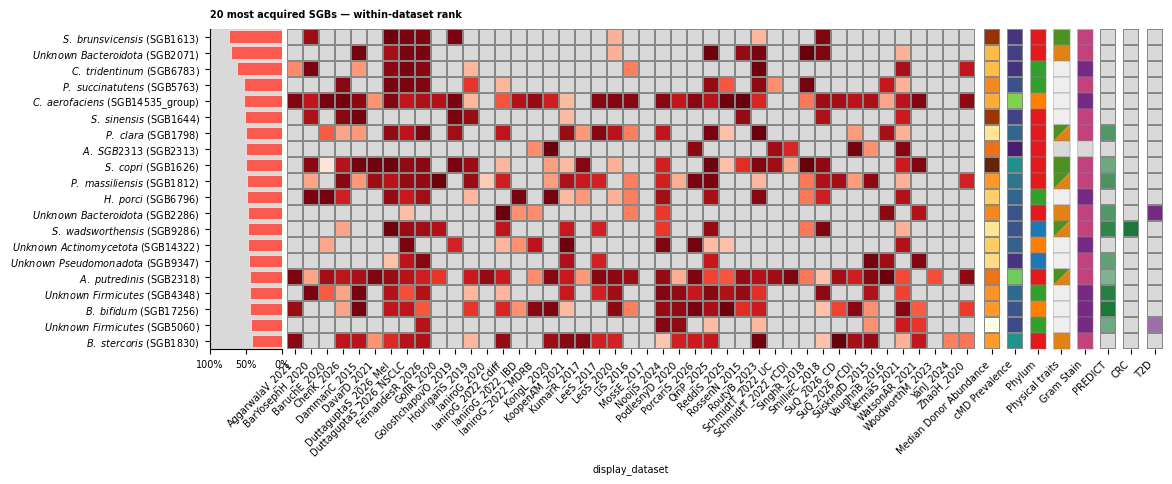

Saved sgb_heatmap_top20_rank.svg  (270mm wide, 113mm tall, 20 SGBs)
Saved sgb_heatmap_bottom20_rank.svg  (270mm wide, 113mm tall, 20 SGBs)


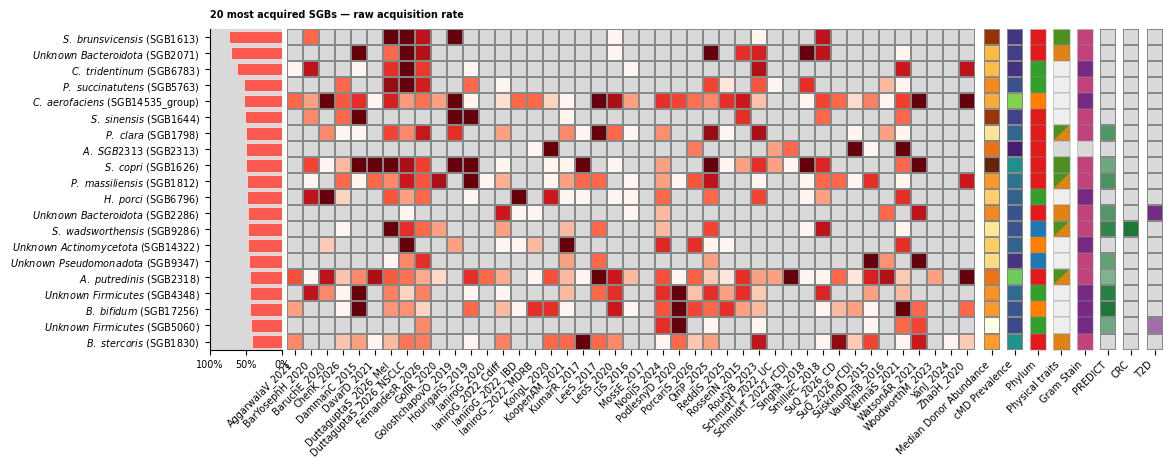

Saved sgb_heatmap_top20_raw.svg  (270mm wide, 113mm tall, 20 SGBs)
Saved sgb_heatmap_bottom20_raw.svg  (270mm wide, 113mm tall, 20 SGBs)
Saved sgb_heatmap_legend.svg


In [41]:
"""
SGB acquisition heatmaps
=========================
Produces 4 heatmap panels + 1 shared legend as standalone SVGs:

  1. sgb_heatmap_top20_rank.svg     - 20 most-acquired SGBs,  central heatmap = within-dataset RANK
  2. sgb_heatmap_bottom20_rank.svg  - 20 least-acquired SGBs, central heatmap = within-dataset RANK
  3. sgb_heatmap_top20_raw.svg      - 20 most-acquired SGBs,  central heatmap = RAW acquisition rate
  4. sgb_heatmap_bottom20_raw.svg   - 20 least-acquired SGBs, central heatmap = RAW acquisition rate
  5. sgb_heatmap_legend.svg         - one shared legend for all four panels

Both the top and bottom sets are restricted to SGBs observed in at least
MIN_DATASETS_PER_SGB datasets *before* ranking/selecting, so each panel is
guaranteed to contain exactly N_SGBS (20) rows.

Expected input globals (build/load these before running):
  acquisition_df         - long-format df with columns: sgb, display_dataset, acquisition_rate
  combined_df             - one row per sgb, incl. 'combined_transmissibility'
  combined_df_annotated   - one row per sgb, incl. 'phylum', 'mean_atleast2_CHM', 'median_donor_abundance'
  traitar                 - TRAITAR trait table, incl. 'sgb', trait/gram columns
  bodysite_props           - per-SGB body-site prevalence proportions, incl. 'SGB_ID', 'stool', ...
  crc, t2d                 - disease-association tables, incl. 'sgb', 'eff_size_corrected', 'pval_corrected'
  sgb_to_tax               - dict/Series mapping 't__SGBxxxx' -> full pipe-delimited taxonomy string
"""

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.patches import Polygon
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
plt.rcParams['svg.fonttype'] = 'none'

# ── Colour maps ───────────────────────────────────────────────────────────
cmap_main      = 'Reds'      # main heatmap colour (rank OR raw, depending on panel — see below)
cmap_abundance = 'YlOrBr'    # median donor abundance — warm palette, distinct from stool's viridis and Reds
cmap_stool     = 'viridis'   # stool prevalence — distinct from main heatmap and abundance

# Purple-green diverging palette, used consistently for all signed annotations
cmap_diverging = LinearSegmentedColormap.from_list(
    'purple_green', ['#762a83', '#f7f7f7', '#1b7837'], N=256
)
cmap_chm     = cmap_diverging
cmap_disease = cmap_diverging

GREY_BG = '#d9d9d9'   # unified grey for all blank/masked cells
NA_COLOR = '#d9d9d9'
NO_TRAIT_COLOR = '#eeeeee'

cmap_chm.set_bad(color=GREY_BG)
cmap_disease.set_bad(color=GREY_BG)

PHYLUM_COLORS = {
    "Bacteroidota": "#E31A1C",     # red
    "Pseudomonadota": "#1F78B4",   # blue
    "Firmicutes": "#33A02C",       # green
    "Bacillota": "#33A02C",        # (synonym for Firmicutes, same color)
    "Actinomycetota": "#FF7F00",   # orange
    "Actinobacteria": "#FF7F00",   # (older synonym, same color)
}

# ── TRAITAR trait colors ────────────────────────────────────────────────────
# Gram positive/negative get their own dedicated binary column (see
# draw_gram_column), so the multi-trait TRAITAR column only considers the
# remaining traits and is capped at showing 2 simultaneous traits.
TRAITAR_MULTI_COLS = ['Motility', 'Hydrogen sulfide', 'Spore formation']
GRAM_COLS = ['Gram positive', 'Gram negative']
TRAITAR_MULTI_COLS = ['Motility', 'Hydrogen sulfide', 'Spore formation', 'Casein hydrolysis']

TRAIT_COLORS = {
    'Spore formation':   '#b8860b',
    'Motility':          '#2f9c95',
    'Hydrogen sulfide':  '#4d9221',
    'Casein hydrolysis': '#e08214',   # new
    'Gram negative':     '#c2427e',
    'Gram positive':     '#762a83',
}

# ── Column display names ────────────────────────────────────────────────
COLUMN_LABELS = {
    'traitar':   'Physical traits',
    'gram':      'Gram Stain',
    'abundance': 'Median Donor Abundance',
    'stool':     'cMD Prevalence',
    'chm':       'PREDICT',
    'crc':       'CRC',
    't2d':       'T2D',
    'phylum':    'Phylum',
}

# ── Global font size for export ─────────────────────────────────────────────
plt.rcParams.update({'font.size': 7})
FS = 7  # single source of truth for all fontsize= calls below

# ── Selection knobs ──────────────────────────────────────────────────────
MIN_DATASETS_PER_SGB = 8   # an SGB must appear in at least this many datasets to be eligible
N_SGBS = 20                 # exact number of SGBs shown per top/bottom panel


# ─────────────────────────────────────────────────────────────────────────
# Matrix builders
# ─────────────────────────────────────────────────────────────────────────
def build_raw_matrix(sgb_list, acquisition_df, datasets):
    """Raw acquisition-rate matrix (SGB x dataset) — the un-ranked value as
    reported in acquisition_df, used for the 'raw' pair of panels."""
    rows = []
    for sgb in sgb_list:
        row = {}
        for ds in datasets:
            subset = acquisition_df[
                (acquisition_df['sgb'] == sgb) &
                (acquisition_df['display_dataset'] == ds)
            ]
            row[ds] = subset['acquisition_rate'].values[0] if len(subset) else np.nan
        rows.append(row)
    return pd.DataFrame(rows, index=sgb_list)


def compute_full_rank_matrix(acquisition_df, datasets):
    """Rank every SGB's acquisition rate *within its dataset*, using the full
    population of SGBs observed in that dataset (not just whatever subset of
    SGBs ends up in a given top/bottom-20 panel — ranking against only 20
    rows would just trivially relabel them 1st-20th and throw away the
    information about how they sit relative to everything else in that
    dataset).

    Returns a percentile-rank matrix (SGB x dataset) where, within each
    dataset column:
      - 1.0  = the SGB with the single highest acquisition rate in that dataset
      - ~0.0 = the SGB with the lowest acquisition rate in that dataset
    NaN is preserved for SGB/dataset combinations with no data.
    """
    full_matrix = acquisition_df.pivot_table(
        index='sgb', columns='display_dataset', values='acquisition_rate'
    )
    full_matrix = full_matrix.reindex(columns=datasets)
    rank_matrix = full_matrix.rank(axis=0, method='average', ascending=True, pct=True)
    return rank_matrix


# ── Species name lookup, built from the metaphlan taxonomy strings ─────────
_PLACEHOLDER_RE = re.compile(r'^[A-Za-z]{1,4}GB\d+')


def _is_placeholder_taxon(name):
    if not name:
        return True
    n = name.strip()
    if n.lower() in ('', 'unclassified', 'unknown'):
        return True
    if _PLACEHOLDER_RE.match(n):
        return True
    return False


def build_sgb_to_species(sgb_to_tax):
    """
    sgb_to_tax maps 't__SGBxxxx' -> full pipe-delimited taxonomy string, e.g.
    'k__Bacteria|p__Firmicutes|...|g__Blautia|s__Blautia_wexlerae|t__SGB1836'
    Species is the second-to-last level (s__...). If that (or genus, etc.) is
    an unresolved genome-bin placeholder, fall back to the deepest resolved
    level, e.g. 'unknown Bacteroidota' when only the phylum is known.
    """
    species = {}
    for sgb, tax_str in sgb_to_tax.items():
        levels = {}
        for part in tax_str.split('|'):
            if '__' in part:
                lvl, name = part.split('__', 1)
                levels[lvl] = name

        s_level = levels.get('s')
        if s_level and not _is_placeholder_taxon(s_level):
            species[sgb] = s_level.replace('_', ' ')
        else:
            label = None
            for lvl_code in ['g', 'f', 'o', 'c', 'p', 'k']:
                val = levels.get(lvl_code)
                if val and not _is_placeholder_taxon(val):
                    label = f"unknown {val.replace('_', ' ')}"
                    break
            species[sgb] = label if label else 'Unclassified'
    return pd.Series(species)


def _abbreviate_species(species):
    """'Blautia wexlerae' -> 'B. wexlerae'. Leaves 'Unknown ...' / 'Unclassified' untouched."""
    if species.startswith('Unknown ') or species == 'Unclassified':
        return species
    parts = species.split(' ', 1)
    if len(parts) == 2:
        genus, rest = parts
        return f"{genus[0]}. {rest}"
    return species


def get_sgb_labels(sgb_list, sgb_to_species):
    """Build y-tick labels as 'G. species (SGB_ID)', all italicized.
    'Unknown <Level>' fallback labels are italicized too, just capitalized,
    and left un-abbreviated since there's no genus to shorten."""
    labels = []
    for sgb in sgb_list:
        sgb_short = sgb.replace('t__', '')
        species = sgb_to_species.get(sgb, 'Unclassified')
        if species.startswith('unknown '):
            species = 'Unknown ' + species[len('unknown '):]
        species = _abbreviate_species(species)
        species_math = species.replace(' ', '\\ ')
        labels.append(f"${species_math}$ ({sgb_short})")
    return labels


_GROUP_SUFFIX_RE = re.compile(r'_group$')


def _base_sgb_id(sgb):
    """Strip a trailing '_group' suffix, e.g. 'SGB_14535_group' -> 'SGB_14535'.

    Grouped SGBs don't get their own entries in the TRAITAR (traits/Gram),
    PREDICT (CHM), CRC, or T2D annotation tables — those are keyed on the
    individual (ungrouped) SGB id, so lookups in those tables fall back to
    the base id. The main heatmap, donor abundance, stool prevalence, and
    phylum columns ARE correctly annotated at the group level already, so
    those keep using the full (possibly '_group'-suffixed) id as-is — this
    helper is only called from the four lookup functions below.
    """
    return _GROUP_SUFFIX_RE.sub('', sgb)


# ─────────────────────────────────────────────────────────────────────────
# Annotation-column data lookups
# ─────────────────────────────────────────────────────────────────────────
def get_traits_present(sgb_list, traitar):
    traitar_idx = traitar.set_index('sgb')
    result = {}
    for sgb in sgb_list:
        lookup_id = _base_sgb_id(sgb)
        if lookup_id in traitar_idx.index:
            traits = []
            for col in TRAITAR_MULTI_COLS:
                if col in traitar_idx.columns:
                    val = traitar_idx.loc[lookup_id, col]
                    if pd.notna(val) and val == 1:
                        traits.append(col)
            result[sgb] = traits
        else:
            result[sgb] = None
    return result


def get_gram_status(sgb_list, traitar):
    """Returns 'positive' / 'negative' / 'none' (neither flagged) / None (no TRAITAR data) per SGB."""
    traitar_idx = traitar.set_index('sgb')
    result = {}
    for sgb in sgb_list:
        lookup_id = _base_sgb_id(sgb)
        if lookup_id in traitar_idx.index:
            pos = traitar_idx.loc[lookup_id, 'Gram positive'] if 'Gram positive' in traitar_idx.columns else np.nan
            neg = traitar_idx.loc[lookup_id, 'Gram negative'] if 'Gram negative' in traitar_idx.columns else np.nan
            if pd.notna(pos) and pos == 1:
                result[sgb] = 'positive'
            elif pd.notna(neg) and neg == 1:
                result[sgb] = 'negative'
            else:
                result[sgb] = 'none'
        else:
            result[sgb] = None
    return result


def get_stool_prevalence_series(sgb_list, bodysite_props):
    """Continuous stool-sample prevalence (proportion, 0-1) per SGB, from bodysite_props
    (columns: SGB_ID, stool, milk, oralcavity, skin, vagina, nasalcavity)."""
    bp = bodysite_props.set_index('SGB_ID')
    vals = []
    for sgb in sgb_list:
        vals.append(bp.loc[sgb, 'stool'] if sgb in bp.index else np.nan)
    return pd.Series(vals, index=sgb_list, dtype=float)


def get_chm_series(sgb_list, combined_df_annotated):
    ann = combined_df_annotated.set_index('sgb')
    return pd.Series(
        [ann.loc[_base_sgb_id(s), 'mean_atleast2_CHM'] if _base_sgb_id(s) in ann.index else np.nan for s in sgb_list],
        index=sgb_list
    )


def get_abundance_series(sgb_list, combined_df_annotated):
    ann = combined_df_annotated.set_index('sgb')
    return pd.Series(
        [ann.loc[s, 'median_donor_abundance'] if s in ann.index else np.nan for s in sgb_list],
        index=sgb_list
    )


def get_disease_series(sgb_list, disease_df, sig_threshold=0.05):
    d = disease_df.set_index('sgb')
    vals = []
    for s in sgb_list:
        lookup_id = _base_sgb_id(s)
        if lookup_id in d.index:
            eff, pcor = d.loc[lookup_id, 'eff_size_corrected'], d.loc[lookup_id, 'pval_corrected']
            vals.append(eff if pcor < sig_threshold else np.nan)
        else:
            vals.append(np.nan)
    return pd.Series(vals, index=sgb_list)


def get_phylum_series(sgb_list, combined_df_annotated):
    ann = combined_df_annotated.set_index('sgb')
    phyla = []
    for s in sgb_list:
        p = ann.loc[s, 'phylum'] if s in ann.index else 'Other'
        phyla.append(p if p in PHYLUM_COLORS else 'Other')
    return pd.Series(phyla, index=sgb_list)


# ─────────────────────────────────────────────────────────────────────────
# Annotation-column drawing
# ─────────────────────────────────────────────────────────────────────────
def draw_traitar_column(ax, sgb_list, traitar, label=None):
    label = label or COLUMN_LABELS['traitar']
    ax.set_facecolor(GREY_BG)
    traits_by_sgb = get_traits_present(sgb_list, traitar)
    n = len(sgb_list)

    for i, sgb in enumerate(sgb_list):
        traits = traits_by_sgb[sgb]
        y0, y1 = i - 0.5, i + 0.5
        x0, x1 = -0.5, 0.5

        if traits is None:
            ax.add_patch(plt.Rectangle((x0, y0), 1, 1, facecolor=NA_COLOR,
                                        edgecolor='#888888', linewidth=0.35))
        elif len(traits) == 0:
            ax.add_patch(plt.Rectangle((x0, y0), 1, 1, facecolor=NO_TRAIT_COLOR,
                                        edgecolor='#888888', linewidth=0.35))
        elif len(traits) == 1:
            ax.add_patch(plt.Rectangle((x0, y0), 1, 1, facecolor=TRAIT_COLORS[traits[0]],
                                        edgecolor='#888888', linewidth=0.35))
        else:
            if len(traits) > 2:
                print(f"Warning: {sgb} has {len(traits)} traits present; showing first 2 only")
                traits = traits[:2]
            c1, c2 = TRAIT_COLORS[traits[0]], TRAIT_COLORS[traits[1]]
            tri1 = Polygon([(x0, y0), (x1, y0), (x0, y1)], closed=True, facecolor=c1, edgecolor='none')
            tri2 = Polygon([(x1, y0), (x1, y1), (x0, y1)], closed=True, facecolor=c2, edgecolor='none')
            ax.add_patch(tri1)
            ax.add_patch(tri2)
            ax.add_patch(plt.Rectangle((x0, y0), 1, 1, fill=False, edgecolor='#888888', linewidth=0.35))

    ax.set_xlim(-0.5, 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_aspect('equal')  # force square cells regardless of the gridspec slot width
    ax.set_xticks([0])
    ax.set_xticklabels([label], rotation=45, ha='right', fontsize=FS)
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor('#cccccc'); spine.set_linewidth(0.5)


def draw_gram_column(ax, sgb_list, traitar, label=None):
    """Dedicated binary column for Gram stain, separate from the multi-trait TRAITAR column."""
    label = label or COLUMN_LABELS['gram']
    ax.set_facecolor(GREY_BG)
    status_by_sgb = get_gram_status(sgb_list, traitar)
    n = len(sgb_list)

    for i, sgb in enumerate(sgb_list):
        status = status_by_sgb[sgb]
        y0 = i - 0.5
        if status is None:
            color = NA_COLOR
        elif status == 'positive':
            color = TRAIT_COLORS['Gram positive']
        elif status == 'negative':
            color = TRAIT_COLORS['Gram negative']
        else:
            color = NO_TRAIT_COLOR
        ax.add_patch(plt.Rectangle((-0.5, y0), 1, 1, facecolor=color, edgecolor='#888888', linewidth=0.35))

    ax.set_xlim(-0.5, 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_aspect('equal')
    ax.set_xticks([0])
    ax.set_xticklabels([label], rotation=45, ha='right', fontsize=FS)
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor('#cccccc'); spine.set_linewidth(0.5)


def make_traitar_legend_patches():
    patches = [mpatches.Patch(facecolor=TRAIT_COLORS[t], label=t) for t in TRAITAR_MULTI_COLS]
    patches.append(mpatches.Patch(facecolor=NO_TRAIT_COLOR, edgecolor='grey', label='No traits present'))
    patches.append(mpatches.Patch(facecolor=NA_COLOR, edgecolor='grey', label='No data'))
    return patches


def make_gram_legend_patches():
    return [
        mpatches.Patch(facecolor=TRAIT_COLORS['Gram positive'], edgecolor='grey', label='Gram positive'),
        mpatches.Patch(facecolor=TRAIT_COLORS['Gram negative'], edgecolor='grey', label='Gram negative'),
        mpatches.Patch(facecolor=NO_TRAIT_COLOR, edgecolor='grey', label='Neither flagged'),
        mpatches.Patch(facecolor=NA_COLOR, edgecolor='grey', label='No data'),
    ]


def plot_single_col_heatmap(ax, values, cmap, vmin, vmax, label):
    """Single-column heatmap strip, no numeric annotations."""
    ax.set_facecolor(GREY_BG)
    df_col = pd.DataFrame(values, columns=[label])
    sns.heatmap(
        df_col, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
        cbar=False, linewidths=0.35, linecolor='#888888',
        mask=df_col.isna(), square=True,
        xticklabels=[label], yticklabels=False
    )
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=FS)
    ax.set_ylabel('')
    return ax


def plot_abundance_column(ax, values, label='Median RA', cmap=cmap_abundance):
    ax.set_facecolor(GREY_BG)
    vals = np.asarray(values, dtype=float)
    log_vals = np.log10(vals + 1e-6)

    valid = log_vals[~np.isnan(log_vals)]
    vmin, vmax = (float(valid.min()), float(valid.max())) if len(valid) else (0.0, 1.0)

    df_col = pd.DataFrame(log_vals, columns=[label])
    sns.heatmap(
        df_col, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
        cbar=False, linewidths=0.35, linecolor='#888888',
        mask=df_col.isna(), square=True,
        xticklabels=[label], yticklabels=False
    )
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=FS)
    ax.set_ylabel('')
    return vmin, vmax


# ── Physical export size (Nature-style figure) ──────────────────────────────
MM_TO_IN = 1 / 25.4
FIG_WIDTH_MM = 270
FIG_WIDTH_IN = FIG_WIDTH_MM * MM_TO_IN   # ~6.89 in

# Row height tuned so 7pt species labels stay legible without touching —
# scales with the number of SGBs so top20/bottom20 (same n) get the same height.
ROW_HEIGHT_IN = 0.155
MARGIN_IN = 1.35   # room for title + rotated x tick labels top/bottom


def plot_single_panel(matrix, combined_lookup, sgb_list, datasets, title, bar_color,
                       traitar, bodysite_props, combined_df_annotated,
                       crc, t2d, sgb_to_species, filename, show=False):
    """`matrix` is the SGB x dataset table drawn as the central heatmap —
    pass either a within-dataset rank matrix (0-1 percentile) or a raw
    acquisition-rate matrix (0-1 rate); both are plotted identically here
    with cmap_main, vmin=0, vmax=1. Only what the color *means* differs,
    which is why the panel title should say which one it is.

    Exported at a fixed physical size (Nature-style, FIG_WIDTH_MM wide) with
    a 7pt font throughout, and narrow annotation columns sitting flush
    against each other rather than spaced out.
    """

    plt.close('all')  # guard against stale figure/axes state leaking between calls

    datasets = matrix.columns.tolist()
    n_ds = len(datasets)
    n_sgbs = len(sgb_list)
    y_pos = np.arange(n_sgbs)

    sgb_labels = get_sgb_labels(sgb_list, sgb_to_species)

    fig_height_in = n_sgbs * ROW_HEIGHT_IN + MARGIN_IN
    fig = plt.figure(figsize=(FIG_WIDTH_IN, fig_height_in))

    # Narrower annotation columns, sized to sit nearly flush against each other.
    col_widths = {
        'bar':   0.5,
        'heat':  max(n_ds * 0.11, 3),   # tighter cells on the x-axis — rectangular, not square
        'ra':    0.16, 'stool': 0.16, 'phy': 0.16, 'tr': 0.16,
        'gram':  0.16, 'chm': 0.16, 'crc': 0.16, 't2d': 0.16,
    }
    ann_keys = ['ra', 'stool', 'phy', 'tr', 'gram', 'chm', 'crc', 't2d']

    outer_ratios = [col_widths['bar'], col_widths['heat'],
                     sum(col_widths[k] for k in ann_keys)]
    gs_outer = gridspec.GridSpec(1, 3, figure=fig, width_ratios=outer_ratios,
                                  wspace=0.015, top=0.90, bottom=0.18, left=0.08, right=0.98)

    ax = {
        'bar':  fig.add_subplot(gs_outer[0]),
        'heat': fig.add_subplot(gs_outer[1]),
    }
    gs_ann = gridspec.GridSpecFromSubplotSpec(
        1, len(ann_keys), subplot_spec=gs_outer[2],
        width_ratios=[col_widths[k] for k in ann_keys],
        wspace=0.0  # nearly no space between annotation columns
    )
    for i, key in enumerate(ann_keys):
        ax[key] = fig.add_subplot(gs_ann[i])

    ax_bar, ax_heat = ax['bar'], ax['heat']
    ax_ra, ax_stool, ax_phy = ax['ra'], ax['stool'], ax['phy']
    ax_tr, ax_gram, ax_chm, ax_crc, ax_t2d = ax['tr'], ax['gram'], ax['chm'], ax['crc'], ax['t2d']

    # ── 1. Bar chart (no per-bar % labels — axis tick labels already show scale) ──
    ax_bar.set_facecolor(GREY_BG)
    values = combined_lookup.reindex(sgb_list).values
    ax_bar.barh(y_pos, values, color=bar_color, edgecolor='white', linewidth=0.4, height=0.78, zorder=3)
    ax_bar.set_xlim(0, 1)
    ax_bar.invert_xaxis()
    ax_bar.invert_yaxis()
    ax_bar.set_ylim(n_sgbs - 0.5, -0.5)
    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels(sgb_labels, fontsize=FS)
    ax_bar.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax_bar.tick_params(axis='x', labelsize=FS)
    ax_bar.spines[['top', 'right']].set_visible(False)
    ax_bar.set_title(title, fontsize=FS, fontweight='bold', loc='left', pad=8)

    # ── 2. Main heatmap (rank OR raw, depending on what was passed in) ──
    ax_heat.set_facecolor(GREY_BG)
    sns.heatmap(
        matrix, ax=ax_heat, cmap=cmap_main, vmin=0, vmax=1,
        cbar=False, linewidths=0.35, linecolor='#888888',
        mask=matrix.isna(), xticklabels=datasets, yticklabels=False, square=False
    )
    ax_heat.set_ylabel('')
    ax_heat.set_xticklabels(ax_heat.get_xticklabels(), rotation=45, ha='right', fontsize=FS)

    # ── 3. TRAITAR / Gram ──
    draw_traitar_column(ax_tr, sgb_list, traitar)
    draw_gram_column(ax_gram, sgb_list, traitar)

    # ── 3.5. Median donor relative abundance ──
    ra_vals = get_abundance_series(sgb_list, combined_df_annotated).values.astype(float)
    vext_ra_min, vext_ra_max = plot_abundance_column(ax_ra, ra_vals, label=COLUMN_LABELS['abundance'])

    # ── 4. Stool prevalence ──
    stool_vals = get_stool_prevalence_series(sgb_list, bodysite_props).values.astype(float)
    plot_single_col_heatmap(ax_stool, stool_vals, cmap_stool, 0, 1, COLUMN_LABELS['stool'])

    # ── 5. CHM ──
    chm = get_chm_series(sgb_list, combined_df_annotated).values.astype(float)
    chm_flat = chm[~np.isnan(chm)]
    vext_chm = float(np.nanmax(np.abs(chm_flat))) if len(chm_flat) else 1.0
    plot_single_col_heatmap(ax_chm, chm, cmap_chm, -vext_chm, vext_chm, COLUMN_LABELS['chm'])

    # ── 6. CRC ──
    crc_vals = get_disease_series(sgb_list, crc).values.astype(float)
    crc_flat = crc_vals[~np.isnan(crc_vals)]
    vext_crc = float(np.nanmax(np.abs(crc_flat))) if len(crc_flat) else 1.0
    plot_single_col_heatmap(ax_crc, crc_vals, cmap_disease, -vext_crc, vext_crc, COLUMN_LABELS['crc'])

    # ── 7. T2D ──
    t2d_vals = get_disease_series(sgb_list, t2d).values.astype(float)
    t2d_flat = t2d_vals[~np.isnan(t2d_vals)]
    vext_t2d = float(np.nanmax(np.abs(t2d_flat))) if len(t2d_flat) else 1.0
    plot_single_col_heatmap(ax_t2d, t2d_vals, cmap_disease, -vext_t2d, vext_t2d, COLUMN_LABELS['t2d'])

    # ── 8. Phylum strip ──
    ax_phy.set_facecolor(GREY_BG)
    phyla = get_phylum_series(sgb_list, combined_df_annotated)
    for i, (sgb, phylum) in enumerate(phyla.items()):
        color = PHYLUM_COLORS.get(phylum, '#aaaaaa')
        ax_phy.add_patch(plt.Rectangle((-0.5, i - 0.5), 1, 1, facecolor=color, edgecolor='#888888', linewidth=0.35))
    ax_phy.set_xlim(-0.5, 0.5)
    ax_phy.set_ylim(n_sgbs - 0.5, -0.5)
    ax_phy.set_aspect('equal')  # force square cells regardless of the gridspec slot width
    ax_phy.set_xticks([0])
    ax_phy.set_xticklabels([COLUMN_LABELS['phylum']], rotation=45, ha='right', fontsize=FS)
    ax_phy.set_yticks([])
    for spine in ax_phy.spines.values():
        spine.set_edgecolor('#cccccc'); spine.set_linewidth(0.5)

    fig.patch.set_facecolor('white')
    plt.savefig(f'{filename}.svg', bbox_inches='tight', facecolor='white')
    if show:
        plt.show()
    plt.close(fig)
    print(f"Saved {filename}.svg  ({FIG_WIDTH_MM}mm wide, {fig_height_in*25.4:.0f}mm tall, {n_sgbs} SGBs)")

    return vext_chm, vext_crc, vext_t2d, vext_ra_min, vext_ra_max


# ─────────────────────────────────────────────────────────────────────────
def make_legend_png(filename, vext_chm, vext_crc, vext_t2d, vext_ra_min, vext_ra_max,
                    n_tiles=7, tile_w=5.0, tile_h=3.0):
    """Legend built entirely from small rectangular tiles (SVG).
    Categorical entries -> one tile + label each.
    Continuous scales   -> a strip of n_tiles discrete tiles sampled from the cmap,
                           with tick labels under the first / middle / last tile."""

    EDGE = dict(edgecolor='#888888', linewidth=0.35)
    STEP = 42          # horizontal spacing between categorical items
    CONT_STEP = 52     # horizontal spacing between continuous scales
    ROW_H = 13         # vertical spacing between rows

    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.set_xlim(0, 4 * STEP)
    ax.set_ylim(6 * ROW_H, 0)        # y grows downward
    ax.axis('off')

    def swatch_row(y, title, items):
        ax.text(0, y - 2.2, title, fontsize=FS, fontweight='bold', va='bottom')
        for i, (color, label) in enumerate(items):
            x = i * STEP
            ax.add_patch(plt.Rectangle((x, y), tile_w, tile_h, facecolor=color, **EDGE))
            ax.text(x + tile_w + 1.5, y + tile_h / 2, label, fontsize=FS, va='center')

    def tile_strip(x, y, title, cmap, vmin, vmax, tick_labels):
        ax.text(x, y - 2.2, title, fontsize=FS, fontweight='bold', va='bottom')
        cm = plt.get_cmap(cmap) if isinstance(cmap, str) else cmap
        for k in range(n_tiles):
            frac = (k + 0.5) / n_tiles
            ax.add_patch(plt.Rectangle((x + k * tile_w, y), tile_w, tile_h,
                                       facecolor=cm(frac), **EDGE))
        tick_idx = [0, n_tiles // 2, n_tiles - 1]
        for k, lab in zip(tick_idx, tick_labels):
            ax.text(x + (k + 0.5) * tile_w, y + tile_h + 1.2, lab,
                    fontsize=FS - 1, ha='center', va='top')

    # ── categorical rows ──
    swatch_row(1 * ROW_H, f"{COLUMN_LABELS['traitar']}",
               [(TRAIT_COLORS[t], t) for t in TRAITAR_MULTI_COLS] +
               [(NO_TRAIT_COLOR, 'No traits present'), (NA_COLOR, 'No data')][:1])
    # (traitar row has 4 items; 'No data' goes on the Gram row's shared entry below)

    swatch_row(2 * ROW_H, f"{COLUMN_LABELS['gram']}",
               [(TRAIT_COLORS['Gram positive'], 'Gram positive'),
                (TRAIT_COLORS['Gram negative'], 'Gram negative'),
                (NO_TRAIT_COLOR, 'Neither flagged'),
                (NA_COLOR, 'No data')])

    # phylum: merge synonyms that share a colour into one entry
    by_color = {}
    for name, c in PHYLUM_COLORS.items():
        by_color.setdefault(c, []).append(name)
    swatch_row(3 * ROW_H, f"{COLUMN_LABELS['phylum']}",
               [(c, ' / '.join(names)) for c, names in by_color.items()])

    # ── continuous rows (3 per row) ──
    ra_ticks = [f'{(10**t)*100:.2g}%' for t in np.linspace(vext_ra_min, vext_ra_max, 3)]
    scales = [
        ("Acquisition (rank or raw)", cmap_main, 0, 1, ['Low', '', 'High']),
        (f"{COLUMN_LABELS['chm']} (\u03c1)", cmap_chm, -vext_chm, vext_chm,
            [f'{-vext_chm:.2g}', '0', f'{vext_chm:.2g}']),
        (f"{COLUMN_LABELS['crc']} (\u03b2)", cmap_disease, -vext_crc, vext_crc,
            [f'{-vext_crc:.2g}', '0', f'{vext_crc:.2g}']),
        (f"{COLUMN_LABELS['t2d']} (\u03b2)", cmap_disease, -vext_t2d, vext_t2d,
            [f'{-vext_t2d:.2g}', '0', f'{vext_t2d:.2g}']),
        (f"{COLUMN_LABELS['abundance']} (log)", cmap_abundance, vext_ra_min, vext_ra_max, ra_ticks),
        (f"{COLUMN_LABELS['stool']}", cmap_stool, 0, 1, ['0%', '50%', '100%']),
    ]
    for i, (title, cm, vmin, vmax, ticks) in enumerate(scales):
        row, col = divmod(i, 3)
        tile_strip(col * CONT_STEP, (4.4 + row * 1.25) * ROW_H, title, cm, vmin, vmax, ticks)

    plt.savefig(f'{filename}.svg', bbox_inches='tight', facecolor='white')
    plt.close(fig)
    print(f"Saved {filename}.svg")


# ═════════════════════════════════════════════════════════════════════════
# Prepare data
# ═════════════════════════════════════════════════════════════════════════
sgb_to_species = build_sgb_to_species(sgb_to_tax)   # sgb_to_tax built earlier from metaphlan profiles

all_datasets = sorted(acquisition_df['display_dataset'].dropna().unique())

# Within-dataset percentile rank, computed against the FULL per-dataset
# population (not just whichever 20 SGBs end up in a given panel).
full_rank_matrix = compute_full_rank_matrix(acquisition_df, all_datasets)

# t = get_traits_present(top20 + bottom20, traitar)
# over = {s: v for s, v in t.items() if v and len(v) > 2}
# print(len(over), over)

# ── SGB eligibility: must appear in >= MIN_DATASETS_PER_SGB datasets ───────
# Filtering *before* selecting the top/bottom N guarantees each panel ends
# up with exactly N_SGBS rows, rather than selecting N and then possibly
# losing some to a post-hoc filter.
datasets_per_sgb = acquisition_df.groupby('sgb')['display_dataset'].nunique()
eligible_sgbs = datasets_per_sgb[datasets_per_sgb >= MIN_DATASETS_PER_SGB].index

combined_df_eligible = combined_df[combined_df['sgb'].isin(eligible_sgbs)]
combined_df_sorted = combined_df_eligible.sort_values('combined_transmissibility', ascending=False)

top20    = combined_df_sorted.head(N_SGBS)['sgb'].tolist()
bottom20 = combined_df_sorted.tail(N_SGBS)['sgb'].tolist()

assert len(top20) == N_SGBS, (
    f"Only {len(top20)} SGBs eligible (>= {MIN_DATASETS_PER_SGB} datasets) for the top panel; "
    f"need {N_SGBS}. Lower MIN_DATASETS_PER_SGB or check acquisition_df coverage."
)
assert len(bottom20) == N_SGBS, (
    f"Only {len(bottom20)} SGBs eligible (>= {MIN_DATASETS_PER_SGB} datasets) for the bottom panel; "
    f"need {N_SGBS}. Lower MIN_DATASETS_PER_SGB or check acquisition_df coverage."
)

print(f"Top panel: {len(top20)} SGBs (>= {MIN_DATASETS_PER_SGB} datasets each)")
print(f"Bottom panel: {len(bottom20)} SGBs (>= {MIN_DATASETS_PER_SGB} datasets each)")

# ── Rank-based matrices (central heatmap = within-dataset percentile) ──────
top20_rank_matrix    = full_rank_matrix.reindex(index=top20, columns=all_datasets)
bottom20_rank_matrix = full_rank_matrix.reindex(index=bottom20, columns=all_datasets)

# ── Raw-value matrices (central heatmap = raw acquisition rate) ────────────
top20_raw_matrix    = build_raw_matrix(top20, acquisition_df, all_datasets)
bottom20_raw_matrix = build_raw_matrix(bottom20, acquisition_df, all_datasets)

# NOTE: the leftmost bar still shows the *overall* combined acquisition
# score across all datasets — a different, already-aggregated metric from
# either central heatmap (rank or raw, per-dataset).
combined_lookup = combined_df.set_index('sgb')['combined_transmissibility']

# ═════════════════════════════════════════════════════════════════════════
# Generate the 4 panels
# ═════════════════════════════════════════════════════════════════════════
vext_chm_tr, vext_crc_tr, vext_t2d_tr, vext_ra_min_tr, vext_ra_max_tr = plot_single_panel(
    top20_rank_matrix, combined_lookup, top20, all_datasets,
    '20 most acquired SGBs \u2014 within-dataset rank', '#FC5A50',
    traitar, bodysite_props, combined_df_annotated, crc, t2d, sgb_to_species,
    filename='sgb_heatmap_top20_rank', show=True
)

vext_chm_br, vext_crc_br, vext_t2d_br, vext_ra_min_br, vext_ra_max_br = plot_single_panel(
    bottom20_rank_matrix, combined_lookup, bottom20, all_datasets,
    '20 least acquired SGBs \u2014 within-dataset rank', '#d6604d',
    traitar, bodysite_props, combined_df_annotated, crc, t2d, sgb_to_species,
    filename='sgb_heatmap_bottom20_rank', show=False
)

vext_chm_tw, vext_crc_tw, vext_t2d_tw, vext_ra_min_tw, vext_ra_max_tw = plot_single_panel(
    top20_raw_matrix, combined_lookup, top20, all_datasets,
    '20 most acquired SGBs \u2014 raw acquisition rate', '#FC5A50',
    traitar, bodysite_props, combined_df_annotated, crc, t2d, sgb_to_species,
    filename='sgb_heatmap_top20_raw', show=True
)

vext_chm_bw, vext_crc_bw, vext_t2d_bw, vext_ra_min_bw, vext_ra_max_bw = plot_single_panel(
    bottom20_raw_matrix, combined_lookup, bottom20, all_datasets,
    '20 least acquired SGBs \u2014 raw acquisition rate', '#d6604d',
    traitar, bodysite_props, combined_df_annotated, crc, t2d, sgb_to_species,
    filename='sgb_heatmap_bottom20_raw', show=False
)

# ═════════════════════════════════════════════════════════════════════════
# One shared legend — color-scale extents taken across all four panels
# ═════════════════════════════════════════════════════════════════════════
make_legend_png(
    'sgb_heatmap_legend',
    vext_chm=max(vext_chm_tr, vext_chm_br, vext_chm_tw, vext_chm_bw),
    vext_crc=max(vext_crc_tr, vext_crc_br, vext_crc_tw, vext_crc_bw),
    vext_t2d=max(vext_t2d_tr, vext_t2d_br, vext_t2d_tw, vext_t2d_bw),
    vext_ra_min=min(vext_ra_min_tr, vext_ra_min_br, vext_ra_min_tw, vext_ra_min_bw),
    vext_ra_max=max(vext_ra_max_tr, vext_ra_max_br, vext_ra_max_tw, vext_ra_max_bw),
)

In [30]:
def make_legend_png(filename, vext_chm, vext_crc, vext_t2d, vext_ra_min, vext_ra_max,
                    n_tiles=7, tile_w=5.0, tile_h=3.0):
    """Legend built entirely from small rectangular tiles (SVG).
    Categorical entries -> one tile + label each.
    Continuous scales   -> a strip of n_tiles discrete tiles sampled from the cmap,
                           with tick labels under the first / middle / last tile."""

    EDGE = dict(edgecolor='#888888', linewidth=0.35)
    STEP = 42          # horizontal spacing between categorical items
    CONT_STEP = 52     # horizontal spacing between continuous scales
    ROW_H = 13         # vertical spacing between rows

    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.set_xlim(0, 4 * STEP)
    ax.set_ylim(6 * ROW_H, 0)        # y grows downward
    ax.axis('off')

    def swatch_row(y, title, items):
        ax.text(0, y - 2.2, title, fontsize=FS, fontweight='bold', va='bottom')
        for i, (color, label) in enumerate(items):
            x = i * STEP
            ax.add_patch(plt.Rectangle((x, y), tile_w, tile_h, facecolor=color, **EDGE))
            ax.text(x + tile_w + 1.5, y + tile_h / 2, label, fontsize=FS, va='center')

    def tile_strip(x, y, title, cmap, vmin, vmax, tick_labels):
        ax.text(x, y - 2.2, title, fontsize=FS, fontweight='bold', va='bottom')
        cm = plt.get_cmap(cmap) if isinstance(cmap, str) else cmap
        for k in range(n_tiles):
            frac = (k + 0.5) / n_tiles
            ax.add_patch(plt.Rectangle((x + k * tile_w, y), tile_w, tile_h,
                                       facecolor=cm(frac), **EDGE))
        tick_idx = [0, n_tiles // 2, n_tiles - 1]
        for k, lab in zip(tick_idx, tick_labels):
            ax.text(x + (k + 0.5) * tile_w, y + tile_h + 1.2, lab,
                    fontsize=FS - 1, ha='center', va='top')

    # ── categorical rows ──
    swatch_row(1 * ROW_H, f"{COLUMN_LABELS['traitar']}",
               [(TRAIT_COLORS[t], t) for t in TRAITAR_MULTI_COLS] +
               [(NO_TRAIT_COLOR, 'No traits present'), (NA_COLOR, 'No data')][:1])
    # (traitar row has 4 items; 'No data' goes on the Gram row's shared entry below)

    swatch_row(2 * ROW_H, f"{COLUMN_LABELS['gram']}",
               [(TRAIT_COLORS['Gram positive'], 'Gram positive'),
                (TRAIT_COLORS['Gram negative'], 'Gram negative'),
                (NO_TRAIT_COLOR, 'Neither flagged'),
                (NA_COLOR, 'No data')])

    # phylum: merge synonyms that share a colour into one entry
    by_color = {}
    for name, c in PHYLUM_COLORS.items():
        by_color.setdefault(c, []).append(name)
    swatch_row(3 * ROW_H, f"{COLUMN_LABELS['phylum']}",
               [(c, ' / '.join(names)) for c, names in by_color.items()])

    # ── continuous rows (3 per row) ──
    ra_ticks = [f'{(10**t)*100:.2g}%' for t in np.linspace(vext_ra_min, vext_ra_max, 3)]
    scales = [
        ("Acquisition (rank or raw)", cmap_main, 0, 1, ['Low', '', 'High']),
        (f"{COLUMN_LABELS['chm']} (\u03c1)", cmap_chm, -vext_chm, vext_chm,
            [f'{-vext_chm:.2g}', '0', f'{vext_chm:.2g}']),
        (f"{COLUMN_LABELS['crc']} (\u03b2)", cmap_disease, -vext_crc, vext_crc,
            [f'{-vext_crc:.2g}', '0', f'{vext_crc:.2g}']),
        (f"{COLUMN_LABELS['t2d']} (\u03b2)", cmap_disease, -vext_t2d, vext_t2d,
            [f'{-vext_t2d:.2g}', '0', f'{vext_t2d:.2g}']),
        (f"{COLUMN_LABELS['abundance']} (log)", cmap_abundance, vext_ra_min, vext_ra_max, ra_ticks),
        (f"{COLUMN_LABELS['stool']}", cmap_stool, 0, 1, ['0%', '50%', '100%']),
    ]
    for i, (title, cm, vmin, vmax, ticks) in enumerate(scales):
        row, col = divmod(i, 3)
        tile_strip(col * CONT_STEP, (4.4 + row * 1.25) * ROW_H, title, cm, vmin, vmax, ticks)

    plt.savefig(f'{filename}.svg', bbox_inches='tight', facecolor='white')
    plt.close(fig)
    print(f"Saved {filename}.svg")

In [31]:
from scipy.stats import spearmanr

# Merge cMD stool prevalence onto the combined acquisition score, matched by SGB
stool_series = bodysite_props.set_index('SGB_ID')['stool']
merged = (
    combined_df.set_index('sgb')[['combined_transmissibility']]
    .join(stool_series, how='inner')
    .dropna()
)

rho, pval = spearmanr(merged['combined_transmissibility'], merged['stool'])
print(f"Spearman rho = {rho:.3f}, p = {pval:.3g}, n = {len(merged)}")

Spearman rho = 0.088, p = 0.104, n = 345


                       trait       rho             p    n
0              CHM (PREDICT)  0.183464  3.602387e-03  250
1  Non-GI body site presence -0.021785  6.867817e-01  345
2            CRC effect size  0.332534  1.180128e-08  280
3            T2D effect size  0.274890  7.526166e-07  314


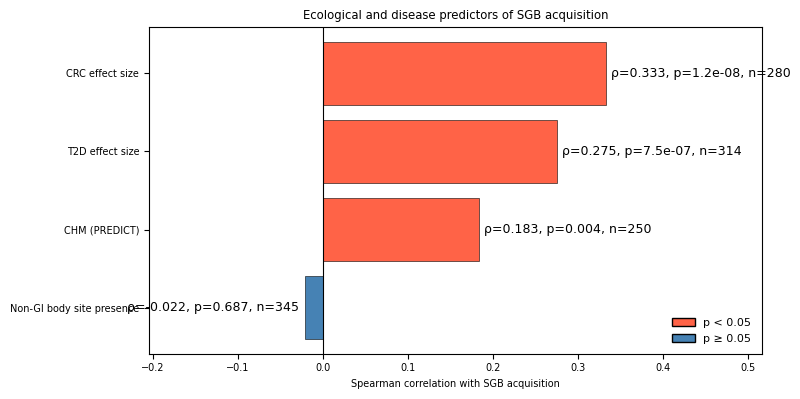

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ─────────────────────────────────────────────────────────────────────────
# This assumes combined_df_annotated, predict, bodysite_counts, crc, and t2d
# are already loaded/built exactly as in the earlier cells — it just re-runs
# each of the four Spearman tests and collects them into one results table.
# ─────────────────────────────────────────────────────────────────────────

def run_spearman(df_left, right_df, right_key_col, right_val_col, left_val_col='residual',
                  left_key_col='sgb', left_strip_t_prefix=True, right_strip_t_prefix=True):
    """Merge df_left with right_df on normalized SGB id, then Spearman(left_val_col, right_val_col)."""
    left = df_left.copy()
    # avoid a silent _x/_y suffix collision if left already has this column
    # (e.g. combined_df_annotated may already carry mean_atleast2_CHM from an earlier merge)
    if right_val_col in left.columns:
        left = left.drop(columns=[right_val_col])
    left['sgb_key'] = left[left_key_col].str.replace('t__', '', regex=False) if left_strip_t_prefix else left[left_key_col]

    right = right_df.copy()
    right['sgb_key'] = right[right_key_col].str.replace('t__', '', regex=False) if right_strip_t_prefix else right[right_key_col]

    merged = left.merge(right[['sgb_key', right_val_col]], on='sgb_key', how='inner')
    tmp = merged[[left_val_col, right_val_col]].dropna()

    rho, p = spearmanr(tmp[right_val_col], tmp[left_val_col])
    return rho, p, len(tmp)


results = []

# ── 1. CHM (PREDICT cardiometabolic health score) ──────────────────────────
predict_key = predict.copy()
predict_key['sgb_key'] = predict_key['SGB']  # already in SGB10115 format
rho, p, n = run_spearman(
    combined_df_annotated, predict_key,
    right_key_col='sgb_key', right_val_col='mean_atleast2_CHM', right_strip_t_prefix=False
)
results.append({'trait': 'CHM (PREDICT)', 'rho': rho, 'p': p, 'n': n})

# ── 2. Non-intestinal (non-GI) body site presence ──────────────────────────
bsc = bodysite_counts.copy()
non_intestinal_sites = ['milk', 'oralcavity', 'skin', 'vagina', 'nasalcavity']
bsc['non_intestinal_present'] = (bsc[non_intestinal_sites].sum(axis=1) >= 4).astype(int)
rho, p, n = run_spearman(
    combined_df_annotated, bsc,
    right_key_col='SGB_ID', right_val_col='non_intestinal_present'
)
results.append({'trait': 'Non-GI body site presence', 'rho': rho, 'p': p, 'n': n})

# ── 3. CRC association ──────────────────────────────────────────────────────
rho, p, n = run_spearman(
    combined_df_annotated, crc,
    right_key_col='sgb', right_val_col='eff_size_corrected'
)
results.append({'trait': 'CRC effect size', 'rho': rho, 'p': p, 'n': n})

# ── 4. T2D association ──────────────────────────────────────────────────────
rho, p, n = run_spearman(
    combined_df_annotated, t2d,
    right_key_col='sgb', right_val_col='eff_size_corrected'
)
results.append({'trait': 'T2D effect size', 'rho': rho, 'p': p, 'n': n})

results = pd.DataFrame(results)
print(results)

# ── Plot ─────────────────────────────────────────────────────────────────
results = results.sort_values('rho')
colors = ['tomato' if p < 0.05 else 'steelblue' for p in results['p']]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(results['trait'], results['rho'], color=colors, edgecolor='black', linewidth=0.4)

# pad the x-axis so text labels never get clipped, and place each label
# outside the bar tip on whichever side the bar points toward
span = results['rho'].abs().max()
pad = span * 0.12 if span > 0 else 0.05
ax.set_xlim(results['rho'].min() - span * 0.55, results['rho'].max() + span * 0.55)

for i, (_, row) in enumerate(results.iterrows()):
    p_str = f"p={row['p']:.1e}" if row['p'] < 1e-3 else f"p={row['p']:.3f}"
    label = f"ρ={row['rho']:.3f}, {p_str}, n={row['n']}"
    if row['rho'] >= 0:
        ax.text(row['rho'] + pad * 0.15, i, label, va='center', ha='left', fontsize=9)
    else:
        ax.text(row['rho'] - pad * 0.15, i, label, va='center', ha='right', fontsize=9)

ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Spearman correlation with SGB acquisition')
ax.set_title('Ecological and disease predictors of SGB acquisition')

# significance legend
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='tomato', edgecolor='black', label='p < 0.05'),
    Patch(facecolor='steelblue', edgecolor='black', label='p ≥ 0.05'),
], loc='lower right', fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig('spearman_acquisition_summary.png', dpi=250, bbox_inches='tight')
plt.show()